<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/HybridQNN_CompoundAdversarialDefence_Yocam2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid classical-quantum network under compounded adversarial attacks and adversarial training: Yocam et al. (2025) step by step

This notebook re-implements, runs and checks the **only original experiment** of

> Eric Yocam, Anthony Rizi, Mahesh Kamepalli, Varghese Vaidyan, Yong Wang and Gurcan Comert,
> "Quantum Adversarial Machine Learning and Defense Strategies: Challenges and Opportunities",
> in: *Quantum-secure neural networks / book chapter*, Springer, 2025 (arXiv preprint dated 18 December 2024).
> DOI 10.1007/978-3-032-11153-1_4. https://doi.org/10.1007/978-3-032-11153-1_4

The paper is mostly a **survey** (taxonomy of quantum-classical attacks, defence strategies, security/privacy/trust design guidelines).
Its Section 3, "Classical-quantum empirical study", is a real experiment and is what this notebook rebuilds: a **hybrid neural network (HNN)**,
a small CNN whose features are fed into a simulated circuit of RY rotations and CNOT gates, trained on MNIST and EMNIST "Digits", attacked
with **three compounded white-box attacks** (FGSM+CW, FGSM+PGD, CW+PGD) and defended with **adversarial training** (paper Tables 4 and 5, Figs. 8 and 9).
The survey sections are summarised in one short cell below; they contain nothing that can be run.

The paper publishes no code and leaves the qubit count, circuit depth, the quantum-classical fusion, the definition of a "compounded" attack and
all attack strengths (epsilons) open. Every such place is marked `# CHOICE:` in the code and listed in the table "What follows the paper and what had to be chosen".
Because of this, **only the qualitative pattern of Table 5 can be checked**, not its exact percentages; the last sections say so explicitly.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs PennyLane (pinned, used only to
cross-check and draw the circuit); if Colab asks to restart the session, restart and run all again. No GPU, no IBM Quantum account and no Hugging Face
token are needed (MNIST and EMNIST are public; if you ever point the code at a gated dataset, put your own token under Colab *Secrets* as `HF_TOKEN`).

**Runtime.** `FAST_MODE = True` (class demo: 1,500 MNIST / 4,000 EMNIST training images, 300 test images each, 10 epochs, 250 adversarial training images per attack) is dominated by the 50-step CW attack and
needs about 25 to 30 minutes of CPU time on an idle machine. The run recorded in this notebook took 106 minutes of wall-clock time because the CPU was shared with about ten other jobs. `FAST_MODE = False` uses the paper's MNIST sizes, 10 epochs and larger adversarial sets; the budgets are in the configuration cell
and the measured runtime is printed in the last cell.

**What you get at the end.** Trained hybrid and classical networks, loss curves, the paper's Fig. 8 / Fig. 9 / Table 5 re-drawn for both datasets, a classical
CNN baseline attacked and defended on identical inputs, an epsilon-sensitivity study, the angles that really enter the quantum circuit, and a verdict per claim.

## The paper in one page

**Problem.** Quantum neural networks (QNNs) are expected to face adversarial attacks, but running QNNs needs scarce hardware. The authors ask whether a
*white-box, targeted, compounded* (WTC) attack, i.e. a combination of two classical white-box attacks, hurts a **hybrid** classical-quantum network, and whether
**adversarial training** protects it.

**Survey part (Sections 1, 2, 4-8, not rerun).** Taxonomy of quantum-classical attacks (white-box vs black-box, targeted vs untargeted, distinct vs compounded; poisoning,
perturbation, inference, evasion, square attacks), four defence families for QNNs (quantum-assisted defence against adversarial AI, quantum GAN / variational QGAN, quantum error
correction, quantum encryption; trade-offs in Table 6) and three "quantum-secure design principles" (post-quantum cryptography, quantum-resistant architectures, transparent and
accountable deployment) with security, privacy and trust guidelines.

**Experiment (Section 3, rebuilt here).**
* **Model (Table 4).** HNN, "4 layers", batch 64, 10 epochs, ReLU and log-softmax, NLL loss, Adam, learning rate 0.001, a digit classifier with outputs [0, 9].
  A CNN extracts features that feed a Cirq circuit: `cirq.ry` rotations "alternating between the angles theta and phi" on every qubit and `CNOT` between neighbours; the number of qubits
  "is determined based on the output dimension of the model"; theta and phi are trainable; the circuit output is "combined with the classical model's predictions".
* **Data (Table 4).** MNIST: 12,665 training and 2,115 test images (these are exactly the numbers of the digits **0 and 1** in MNIST: 5,923 + 6,742 and 980 + 1,135);
  EMNIST "Digits": 48,000 training and 8,000 test images (a class-balanced 20 percent subset of the 240,000 / 40,000 images).
* **Attacks.** PyTorch and *Torchattacks*: FGSM+PGD, FGSM+CW and CW+PGD, white-box, compounded.
* **Procedures.** 11 steps without defence (train, evaluate, attack, evaluate) and 16 steps with adversarial training (generate adversarial samples with the compounded
  attack, merge them with the normal samples, retrain, evaluate, attack the retrained model, evaluate).
* **Claims (Table 5, Figs. 8 and 9).** Accuracy clean / no defence / with defence:

| Dataset | Attack | Clean | No defence | With defence | Loss clean | Loss no defence | Loss with defence |
|---|---|---|---|---|---|---|---|
| MNIST | FGSM+CW | 100 % | 16 % | 100 % | 0.000641 | 3.93 | 0.00759 |
| MNIST | FGSM+PGD | 100 % | 5 % | 100 % | 0.0029 | 7.88 | 0.00848 |
| MNIST | CW+PGD | 100 % | 92 % | 100 % | 0.00278 | 0.134 | 0.0116 |
| EMNIST | FGSM+CW | 100 % | 12 % | 100 % | 0.00164 | 4.33 | 0.00218 |
| EMNIST | FGSM+PGD | 100 % | 25 % | 100 % | 0.000562 | 3.07 | 0.00315 |
| EMNIST | CW+PGD | 98 % | 77 % | 100 % | 0.0416 | 0.478 | 0.00131 |

The paper concludes that (i) the HNN, like a CNN, is vulnerable to WTC attacks, (ii) CW+PGD is the least damaging combination and FGSM-containing combinations the most damaging,
(iii) adversarial training restores the accuracy to about 100 %.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Framework | PyTorch, Cirq, Torchattacks | PyTorch; the circuit is an exact real-amplitude statevector simulator written in PyTorch (fast and differentiable), **asserted equal to a PennyLane QNode** (Cirq is not installed here; both are exact simulators of the same gate list); the three attacks are re-implemented with Torchattacks semantics (Torchattacks itself is not installed) |
| MNIST data | "10,000 + 60,000"; Table 4: 12,665 train / 2,115 test | digits 0 and 1 only (these counts match exactly, asserted in the code); the classifier still has 10 outputs as Table 4 says. FAST_MODE uses random subsets |
| EMNIST data | 48,000 train / 8,000 test "Digits" | class-balanced random subset of the official EMNIST Digits files with exactly these sizes; FAST_MODE and the default full budgets use smaller random subsets (see config) |
| Network | "4 layers", ReLU + log-softmax, NLL | CNN with 4 learnable layers (conv 1-8, conv 8-16, linear 400-64, linear 64-10), ReLU, 2x2 max-pool, log-softmax output; CHOICE of widths and kernel sizes |
| Qubits and depth | qubits = output dimension of the model; depth not given | 10 qubits (10 CNN outputs); `Q_BLOCKS = 2` blocks of [RY on every qubit, CNOT chain 0-1, 1-2, ..., 8-9]; circuit depth 14 as counted by PennyLane (printed in the circuit section; the RY layer of a block overlaps with the tail of the previous CNOT chain). CHOICE |
| Rotation angles | `cirq.ry`, "alternating between theta and phi", trainable | qubit q gets RY(theta_l) if q is even, RY(phi_l) if q is odd, one (theta_l, phi_l) pair per block, initialised uniformly in [0, 2 pi). CHOICE: the sharing of angles over qubits |
| Data encoding | "extracted features are used as input to the quantum circuit" | the 10 CNN outputs are the angles of RY encoding gates on the 10 qubits applied to |0>. CHOICE |
| Fusion | "output of the quantum circuit is processed and combined with the classical model's predictions" | logits = CNN output + alpha * 5 * <Z_q> (q = 0..9) with a trainable scalar alpha (initial 1), then log-softmax. CHOICE |
| Training | batch 64, 10 epochs, Adam 0.001, NLL | same; FAST_MODE also 10 epochs. 10 percent of the training images are held out as validation set and the epoch with the lowest validation loss is kept ("fit HNN model to lowest loss value", steps 4 and 10); the test set is never used for fitting |
| FGSM | Torchattacks, strength not given | one gradient-sign step, `eps_FGSM = 0.2`, images clipped to [0, 1]. CHOICE, fixed before looking at any result (MNIST convention 0.1 to 0.3; Torchattacks' default 8/255 is almost invisible to a digit classifier) |
| PGD | Torchattacks, strength not given | `eps_PGD = 0.1`, step 0.025, 10 steps, random start, L-infinity. CHOICE, same reason |
| CW | Torchattacks, strength not given | Torchattacks defaults: c = 1, kappa = 0, 50 Adam steps, lr = 0.01, L2, untargeted (the best adversarial image found, otherwise the input is returned). CHOICE |
| Compounded attack | "combination of two attacks"; Sec. 2.4: perturbations coordinated across batches; Sec. 3.1: "FGSM finds an initial perturbation and CW refines it" | **sequential composition**: the second attack starts from the output of the first and has its own budget around that output (FGSM+PGD: up to 0.2 + 0.1 in L-infinity; FGSM+CW: CW from the FGSM image; CW+PGD: PGD from the CW image). Mean L-infinity and L2 of the final perturbations are reported. CHOICE |
| Targeted | title says "targeted" | **untargeted** (the paper measures only whether predictions are wrong, never a target class). CHOICE |
| Adversarial training | steps 7-11: attack, merge normal and adversarial samples, retrain | adversarial versions of `N_ADV` random training images (made by the compounded attack against the first, undefended model) are merged with the **full** clean training set and a fresh model is trained on the union (same seed, same hyper-parameters). CHOICE: subset size `N_ADV`, retraining from scratch |
| Evaluation after defence | steps 13-16: pre-attack accuracy, attack the retrained model, post-attack accuracy | **adaptive** (literal reading): the attack is re-run white-box against the *defended* model (main number). Reported next to it: **static**, the same adversarial test images that were made against the undefended model. The paper does not say which it used |
| Reported loss | NLL | mean NLL of the test set (same images as the accuracy) |
| Seeds, confidence intervals | none | `SEED = 42` everywhere, one training run per cell of the table (more seeds are cheap to add, see exercise 5) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, torch, Pillow and huggingface_hub.
# Only PennyLane has to be added; it is used to cross-check and draw the circuit that the PyTorch simulator executes.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane already present; skipping pip install.")

PennyLane already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE   = True            # True: class demo (small samples, CW dominates the cost). False: paper-sized MNIST, 10 epochs, bigger adversarial sets (hours on a CPU).
SEED        = 42              # CHOICE: the paper gives no seed
DATA_DIR    = "data"          # cache for the downloaded files (relative to the working directory)
IBM_TOKEN   = ""              # not used: the paper simulates everything, there is no hardware cell in this notebook
TORCH_THREADS = 2             # CPU threads for PyTorch (several notebooks may share a machine)

# Table 4 of the paper
BATCH, LR = 64, 1e-3          # batch size 64, Adam learning rate 0.001
N_QUBITS_CFG, Q_BLOCKS = 10, 2   # CHOICE: qubits = number of model outputs (10 digits); 2 blocks of [RY layer + CNOT chain]

# Attack strengths, fixed before any result was looked at (see the "what had to be chosen" table)
ATK = dict(fgsm_eps=0.2,                                   # FGSM step (L-infinity)
           pgd_eps=0.1, pgd_alpha=0.025, pgd_steps=10,     # PGD radius, step, iterations (random start)
           cw_c=1.0, cw_kappa=0.0, cw_steps=50, cw_lr=0.01)  # Torchattacks CW defaults
PAIRS = ["FGSM+CW", "FGSM+PGD", "CW+PGD"]                  # the three compounded attacks of Table 5
SWEEP = [(0.05, 0.05), (0.1, 0.05), (0.2, 0.1), (0.3, 0.15)]   # (FGSM eps, PGD eps) pairs of the sensitivity study; PGD step = eps / 4

if FAST_MODE:
    N_TRAIN = {"MNIST": 1500, "EMNIST": 4000}     # images per dataset incl. the 10 % validation part (paper: 12,665 and 48,000)
    N_TEST  = {"MNIST": 300,  "EMNIST": 300}      # (paper: 2,115 and 8,000)
    EPOCHS  = 10                                  # (paper: 10)
    N_ADV   = 250                                 # training images turned into adversarial examples per attack pair
    N_SWEEP = 100                                 # test images of the epsilon-sensitivity study
else:
    N_TRAIN = {"MNIST": 12665, "EMNIST": 12000}   # MNIST: all digits 0 and 1 as in the paper; EMNIST: 12,000 of the paper's 48,000 (CPU time)
    N_TEST  = {"MNIST": 2115,  "EMNIST": 2000}    # EMNIST: 2,000 of the paper's 8,000
    EPOCHS  = 10
    N_ADV   = 2000
    N_SWEEP = 500
# Paper-sized budgets for a long run on a faster machine: N_TRAIN = {"MNIST": 12665, "EMNIST": 48000}, N_TEST = {"MNIST": 2115, "EMNIST": 8000}, N_ADV = N_TRAIN
VAL_FRACTION = 0.1            # CHOICE: share of the training images used for "fit to the lowest loss value"

In [3]:
import os, io, gzip, time, copy, math, warnings, importlib.metadata as md
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler

# Hugging Face token: only needed for gated datasets. MNIST and EMNIST Digits are public, so an empty token is fine.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

matplotlib.rcParams["figure.dpi"] = 80                     # keeps the saved figures small
torch.set_num_threads(TORCH_THREADS)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
T_START = time.time()
print("torch", torch.__version__, "| pennylane", qml.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)
print("FAST_MODE =", FAST_MODE, "| N_TRAIN", N_TRAIN, "| N_TEST", N_TEST, "| epochs", EPOCHS, "| N_ADV", N_ADV)

torch 2.14.1+cpu | pennylane 0.45.1 | numpy 2.5.4 | pandas 3.0.6
FAST_MODE = True | N_TRAIN {'MNIST': 1500, 'EMNIST': 4000} | N_TEST {'MNIST': 300, 'EMNIST': 300} | epochs 10 | N_ADV 250


## 1. MNIST and EMNIST "Digits", downloaded

Both datasets are public.

* **MNIST**: the official parquet files of the Hugging Face repository `ylecun/mnist` (fallback: `keras.datasets.mnist`).
* **EMNIST Digits**: the official idx files (`emnist-digits-*-idx3-ubyte.gz`) from the mirror `tanganke/emnist_digits` (fallback: `Royc30ne/emnist-digits`).
  The raw files store every image transposed, so the code transposes them back (checked visually in the example-image figure below). The train file is 60 MB,
  so the notebook keeps only the label counts of the full 240,000 / 40,000 images and the images of a class-balanced random subset of the paper's size
  (48,000 training and 8,000 test images, 10 digits with the same number each), caches that, and deletes the raw files.

The paper's MNIST sizes (12,665 / 2,115) are exactly the number of images of digits 0 and 1, so this notebook trains on digits 0 and 1 of MNIST while the
network keeps its 10 outputs (the paper's Table 4: "digit classifier recognizes [0, 9]").

In [4]:
# ---- download / cache MNIST and EMNIST Digits ----
def _read_idx(path):
    with gzip.open(path, "rb") as f:
        b = f.read()
    nd = b[3]; dims = [int.from_bytes(b[4 + 4 * i: 8 + 4 * i], "big") for i in range(nd)]
    return np.frombuffer(b, dtype=np.uint8, offset=4 + 4 * nd).reshape(dims)

def load_mnist():
    cache = os.path.join(DATA_DIR, "mnist_cache.npz")
    if os.path.exists(cache):
        z = np.load(cache); return {k: z[k] for k in z.files if k != "origin"}, str(z["origin"]) + " (cached)"
    try:
        from huggingface_hub import hf_hub_download
        out = {}
        for sp in ("train", "test"):
            p = hf_hub_download("ylecun/mnist", f"mnist/{sp}-00000-of-00001.parquet", repo_type="dataset",
                                local_dir=os.path.join(DATA_DIR, "hf"), token=HF_TOKEN or None)
            df = pd.read_parquet(p)
            out["X" + sp] = np.stack([np.asarray(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]]).astype(np.uint8)
            out["y" + sp] = df["label"].to_numpy().astype(np.int64)
        origin = "huggingface:ylecun/mnist"
    except Exception as e:
        print("Hugging Face download failed (%s: %s); falling back to keras.datasets" % (type(e).__name__, str(e)[:80]))
        from tensorflow.keras import datasets as kd
        (xtr, ytr), (xte, yte) = kd.mnist.load_data()
        out = dict(Xtrain=xtr, ytrain=ytr.astype(np.int64), Xtest=xte, ytest=yte.astype(np.int64)); origin = "keras.datasets"
    np.savez_compressed(cache, origin=np.array(origin), **out)
    return out, origin

def load_emnist_digits():
    cache = os.path.join(DATA_DIR, "emnist_digits_cache.npz")
    if os.path.exists(cache):
        z = np.load(cache); return {k: z[k] for k in z.files if k != "origin"}, str(z["origin"]) + " (cached)"
    from huggingface_hub import hf_hub_download
    last = None
    for repo, prefix in (("tanganke/emnist_digits", "raw/"), ("Royc30ne/emnist-digits", "")):
        try:
            raw = {}
            for sp in ("train", "test"):
                for kind in ("images-idx3", "labels-idx1"):
                    fn = f"{prefix}emnist-digits-{sp}-{kind}-ubyte.gz"
                    raw[(sp, kind)] = hf_hub_download(repo, fn, repo_type="dataset", local_dir=os.path.join(DATA_DIR, "hf_emnist"),
                                                      token=HF_TOKEN or None)
            origin = "huggingface:" + repo
            break
        except Exception as e:
            last = e; print("download from", repo, "failed:", type(e).__name__, str(e)[:80])
    else:
        raise RuntimeError("EMNIST Digits could not be downloaded") from last
    r = np.random.default_rng(SEED)
    out = {}
    for sp, k in (("train", 4800), ("test", 800)):       # paper: 48,000 train / 8,000 test, class balanced
        X = _read_idx(raw[(sp, "images-idx3")]); y = _read_idx(raw[(sp, "labels-idx1")]).astype(np.int64)
        out["full_shape_" + sp] = np.array(X.shape); out["full_counts_" + sp] = np.bincount(y, minlength=10)
        sel = np.concatenate([r.choice(np.where(y == c)[0], k, replace=False) for c in range(10)])
        sel = sel[r.permutation(len(sel))]
        out["X" + sp] = X[sel].transpose(0, 2, 1).copy()        # EMNIST idx files store images transposed
        out["y" + sp] = y[sel]
    np.savez_compressed(cache, origin=np.array(origin), **out)
    for p in raw.values():                                       # the raw train file is 60 MB: remove it after reading
        try: os.remove(p)
        except OSError: pass
    return out, origin

t0 = time.time()
MN, MN_ORIGIN = load_mnist(); EM, EM_ORIGIN = load_emnist_digits()
print("MNIST  :", MN_ORIGIN, {k: v.shape for k, v in MN.items()})
print("EMNIST :", EM_ORIGIN, {k: tuple(v.shape) for k, v in EM.items()})
print("download / load time: %.0f s" % (time.time() - t0))

mnist/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 15.6MB            

mnist/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mnist/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.60MB            

mnist/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

raw/emnist-digits-train-images-idx3-ubyt(…): reconstructing file:   0%|          |  0.00B / 60.2MB            

...

raw/emnist-digits-test-images-idx3-ubyte(…): reconstructing file:   0%|          |  0.00B / 10.0MB            

raw/emnist-digits-test-images-idx3-ubyte(…): downloading bytes:           |  0.00B            

raw/emnist-digits-test-labels-idx1-ubyte(…): reconstructing file:   0%|          |  0.00B / 20.0kB            

raw/emnist-digits-test-labels-idx1-ubyte(…): downloading bytes:           |  0.00B            

MNIST  : huggingface:ylecun/mnist {'Xtrain': (60000, 28, 28), 'ytrain': (60000,), 'Xtest': (10000, 28, 28), 'ytest': (10000,)}
EMNIST : huggingface:tanganke/emnist_digits {'full_shape_train': (3,), 'full_counts_train': (10,), 'Xtrain': (48000, 28, 28), 'ytrain': (48000,), 'full_shape_test': (3,), 'full_counts_test': (10,), 'Xtest': (8000, 28, 28), 'ytest': (8000,)}
download / load time: 56 s


In [5]:
# ---- build the tensors: class selection, random subsets, train / validation / test ----
def to_t(X):
    return torch.tensor(X, dtype=torch.float32).div_(255.0).unsqueeze(1)          # (N, 1, 28, 28) in [0, 1]

def subset(n, N, r):
    return r.permutation(N)[:min(n, N)]

DS = {}
# MNIST: digits 0 and 1 only (Table 4 sizes 12,665 / 2,115)
mtr = np.isin(MN["ytrain"], (0, 1)); mte = np.isin(MN["ytest"], (0, 1))
print("MNIST digits 0/1: train %d, test %d  -> equals Table 4 (12,665 / 2,115): %s" % (mtr.sum(), mte.sum(), (mtr.sum(), mte.sum()) == (12665, 2115)))
assert (mtr.sum(), mte.sum()) == (12665, 2115)
Xm_tr, ym_tr = MN["Xtrain"][mtr], MN["ytrain"][mtr]; Xm_te, ym_te = MN["Xtest"][mte], MN["ytest"][mte]
DS["MNIST"] = dict(raw=(Xm_tr, ym_tr, Xm_te, ym_te), full_counts_train=np.bincount(MN["ytrain"], minlength=10),
                   full_counts_test=np.bincount(MN["ytest"], minlength=10), full_shape=(len(MN["ytrain"]), len(MN["ytest"])),
                   used_classes=[0, 1], names=[str(i) for i in range(10)], origin=MN_ORIGIN)
DS["EMNIST"] = dict(raw=(EM["Xtrain"], EM["ytrain"], EM["Xtest"], EM["ytest"]), full_counts_train=EM["full_counts_train"],
                    full_counts_test=EM["full_counts_test"], full_shape=(int(EM["full_shape_train"][0]), int(EM["full_shape_test"][0])),
                    used_classes=list(range(10)), names=[str(i) for i in range(10)], origin=EM_ORIGIN)

for name, d in DS.items():
    r = np.random.default_rng(SEED)
    Xtr, ytr, Xte, yte = d["raw"]
    it = subset(N_TRAIN[name], len(Xtr), r); ie = subset(N_TEST[name], len(Xte), r)
    nva = int(round(VAL_FRACTION * len(it)))
    iva, itr = it[:nva], it[nva:]                                   # CHOICE: random 10 % of the sample is the validation part
    d.update(Xtr=to_t(Xtr[itr]), ytr=torch.tensor(ytr[itr]), Xva=to_t(Xtr[iva]), yva=torch.tensor(ytr[iva]),
             Xte=to_t(Xte[ie]), yte=torch.tensor(yte[ie]))
    print(f"{name:6s}: train {len(itr)}, validation {len(iva)}, test {len(ie)} images "
          f"(per class, train: {np.bincount(ytr[itr], minlength=10).tolist()})")

MNIST digits 0/1: train 12665, test 2115  -> equals Table 4 (12,665 / 2,115): True
MNIST : train 1350, validation 150, test 300 images (per class, train: [637, 713, 0, 0, 0, 0, 0, 0, 0, 0])


EMNIST: train 3600, validation 400, test 300 images (per class, train: [371, 356, 345, 356, 359, 359, 369, 358, 356, 371])


## Dataset Exploration and Visualisation

Everything below is computed from the downloaded files: shapes, feature names, original labels and class counts of the **full** datasets, the subsets that the
experiments use, real example images, and two-dimensional projections in which **every point is one real image coloured by its ground-truth digit**.
(The datasets are images, so the projection is a PCA of the pixels; MNIST has no attack-family labels, the "classes" are the ten digits.)

### Shapes, feature names, original labels and class counts

In [6]:
# ---- real-dataset facts: shape, feature names, original labels and class counts ----
for name, d in DS.items():
    ntr, nte = d["full_shape"]
    feat = [f"pixel_{r}_{c}" for r in range(28) for c in range(28)]
    print(f"=== {name} ({d['origin']}) ===")
    print(f"full dataset shape : {ntr:,} training + {nte:,} test images, each 28 x 28 grey-scale = {len(feat)} features")
    print(f"feature names      : {feat[:3]} ... {feat[-1]}  (pixel intensities 0..255, scaled to [0, 1] here)")
    print(f"original labels    : {list(range(10))} (digits)")
    cnt = pd.DataFrame({"digit": range(10), "train (full)": d["full_counts_train"], "test (full)": d["full_counts_test"]}).set_index("digit")
    display(cnt.T)
    used = d["used_classes"]
    print(f"classes the experiment uses : {used}"
          + ("  (Table 4 sizes = digits 0 and 1 of MNIST)" if name == "MNIST" else "  (all ten digits; class-balanced subset of the paper's size is cached)"))
    print(f"experiment subsets          : train {np.bincount(d['ytr'].numpy(), minlength=10).tolist()}, "
          f"validation {np.bincount(d['yva'].numpy(), minlength=10).tolist()}, test {np.bincount(d['yte'].numpy(), minlength=10).tolist()}\n")

=== MNIST (huggingface:ylecun/mnist) ===
full dataset shape : 60,000 training + 10,000 test images, each 28 x 28 grey-scale = 784 features
feature names      : ['pixel_0_0', 'pixel_0_1', 'pixel_0_2'] ... pixel_27_27  (pixel intensities 0..255, scaled to [0, 1] here)
original labels    : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] (digits)


digit,0,1,2,3,4,5,6,7,8,9
train (full),5923,6742,5958,6131,5842,5421,5918,6265,5851,5949
test (full),980,1135,1032,1010,982,892,958,1028,974,1009


classes the experiment uses : [0, 1]  (Table 4 sizes = digits 0 and 1 of MNIST)
experiment subsets          : train [637, 713, 0, 0, 0, 0, 0, 0, 0, 0], validation [72, 78, 0, 0, 0, 0, 0, 0, 0, 0], test [135, 165, 0, 0, 0, 0, 0, 0, 0, 0]

=== EMNIST (huggingface:tanganke/emnist_digits) ===
full dataset shape : 240,000 training + 40,000 test images, each 28 x 28 grey-scale = 784 features
feature names      : ['pixel_0_0', 'pixel_0_1', 'pixel_0_2'] ... pixel_27_27  (pixel intensities 0..255, scaled to [0, 1] here)
original labels    : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] (digits)


digit,0,1,2,3,4,5,6,7,8,9
train (full),24000,24000,24000,24000,24000,24000,24000,24000,24000,24000
test (full),4000,4000,4000,4000,4000,4000,4000,4000,4000,4000


classes the experiment uses : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]  (all ten digits; class-balanced subset of the paper's size is cached)
experiment subsets          : train [371, 356, 345, 356, 359, 359, 369, 358, 356, 371], validation [43, 42, 44, 34, 43, 41, 36, 34, 49, 34], test [39, 29, 35, 33, 24, 31, 26, 28, 28, 27]



### Real class distributions (full datasets and the subsets the models see)

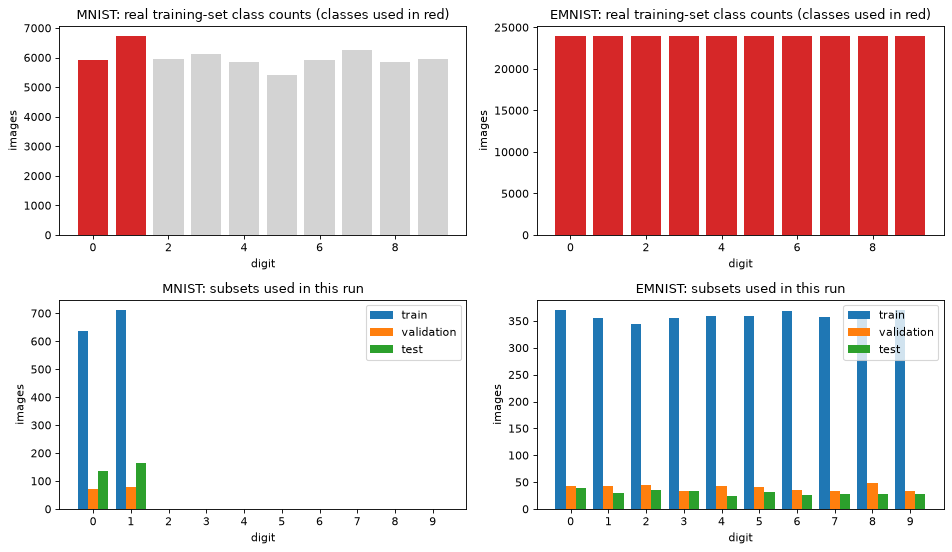

In [7]:
# ---- class distribution of the real datasets (top: full train set, used classes in red) and of the subsets used here (bottom) ----
fig, axs = plt.subplots(2, 2, figsize=(12, 7))
for j, (name, d) in enumerate(DS.items()):
    cols = ["tab:red" if c in d["used_classes"] else "lightgray" for c in range(10)]
    axs[0, j].bar(range(10), d["full_counts_train"], color=cols)
    axs[0, j].set_title(f"{name}: real training-set class counts (classes used in red)"); axs[0, j].set_xlabel("digit"); axs[0, j].set_ylabel("images")
    w = 0.27
    for off, (lab, y) in enumerate((("train", d["ytr"]), ("validation", d["yva"]), ("test", d["yte"]))):
        axs[1, j].bar(np.arange(10) + (off - 1) * w, np.bincount(y.numpy(), minlength=10), width=w, label=lab)
    axs[1, j].set_xticks(range(10)); axs[1, j].set_title(f"{name}: subsets used in this run"); axs[1, j].set_xlabel("digit"); axs[1, j].set_ylabel("images"); axs[1, j].legend()
plt.tight_layout(); plt.show()

### Example images

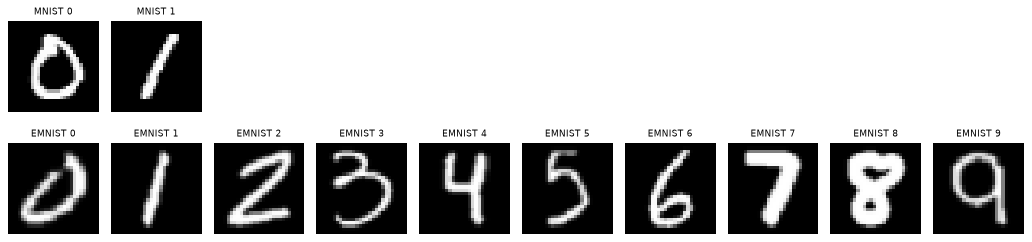

In [8]:
# ---- real example images (rows: digits; EMNIST was transposed back, so the digits stand upright) ----
fig, axs = plt.subplots(2, 10, figsize=(13, 3.2))
for r_, (name, d) in enumerate(DS.items()):
    for c in range(10):
        idx = np.where(d["ytr"].numpy() == c)[0]
        ax = axs[r_, c]; ax.axis("off")
        if len(idx):
            ax.imshow(d["Xtr"][idx[0], 0], cmap="gray", vmin=0, vmax=1); ax.set_title(f"{name} {c}", fontsize=8)
plt.tight_layout(); plt.show()

### 2-D projections of the real images

Panels (a) to (c) for each dataset: (a) the first two principal components of the raw pixels of a random sample of the *full* downloaded training set with all ten original digits
(MNIST 0 to 9 are shown although the experiment only uses 0 and 1); (b) the images of the experiment's training split with the **raw PCA coordinates fitted on that split**;
(c) the same coordinates scaled to $[0, \pi]$ by a scaler fitted on the training split (the range of a rotation angle). The paper's circuit does not encode pixels:
it encodes the **CNN outputs**, so the angles that really enter the circuit are plotted after training in Section 5 (same colours, same style).

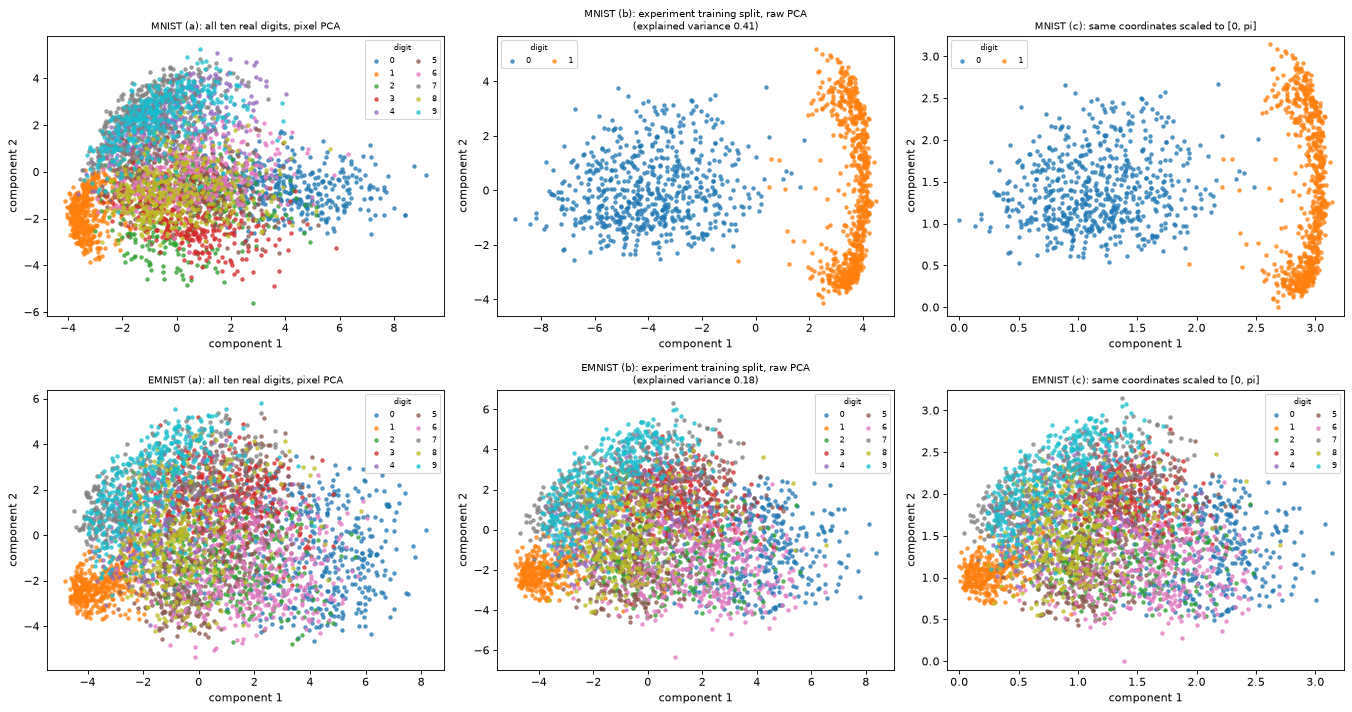

In [9]:
# ---- 2-D scatter plots of REAL images coloured by their ground-truth digit ----
def scatter(ax, Z, y, title, classes):
    cmap = plt.get_cmap("tab10")
    for k in classes:
        m = y == k
        if m.any():
            ax.scatter(Z[m, 0], Z[m, 1], s=9, color=cmap(k), alpha=0.7, label=str(k))
    ax.set_title(title, fontsize=9); ax.set_xlabel("component 1"); ax.set_ylabel("component 2"); ax.legend(fontsize=7, ncol=2, title="digit", title_fontsize=7)

fig, axs = plt.subplots(2, 3, figsize=(17, 9))
PIX_PCA = {}
for r_, (name, d) in enumerate(DS.items()):
    Xtr_raw, ytr_raw = d["raw"][0], d["raw"][1]
    ra = np.random.default_rng(SEED)
    ids = ra.choice(len(Xtr_raw), min(4000, len(Xtr_raw)), replace=False)       # sample of the real training file (all digits present for EMNIST)
    if name == "MNIST":                                                          # show all ten digits of the full MNIST training file
        full_X, full_y = MN["Xtrain"], MN["ytrain"]; ids = ra.choice(len(full_X), 4000, replace=False)
        Xa, ya = full_X[ids].reshape(4000, -1) / 255.0, full_y[ids]
    else:
        Xa, ya = Xtr_raw[ids].reshape(len(ids), -1) / 255.0, ytr_raw[ids]
    pa = PCA(2, random_state=SEED).fit(Xa)
    scatter(axs[r_, 0], pa.transform(Xa), ya, f"{name} (a): all ten real digits, pixel PCA", range(10))
    Xt = d["Xtr"].flatten(1).numpy(); yt = d["ytr"].numpy()
    pca = PCA(2, random_state=SEED).fit(Xt); Z = pca.transform(Xt)                # fitted on the training split only
    scatter(axs[r_, 1], Z, yt, f"{name} (b): experiment training split, raw PCA\n(explained variance {pca.explained_variance_ratio_.sum():.2f})", d["used_classes"])
    sc = MinMaxScaler((0, math.pi)).fit(Z); Zs = sc.transform(Z)                   # scaler fitted on the training split only
    scatter(axs[r_, 2], Zs, yt, f"{name} (c): same coordinates scaled to [0, pi]", d["used_classes"])
    axs[r_, 2].set_xlim(-0.1, math.pi + 0.1); axs[r_, 2].set_ylim(-0.1, math.pi + 0.1)
    PIX_PCA[name] = (pca, sc)
plt.tight_layout(); plt.show()

## 2. The hybrid network and its quantum circuit

**Classical part.** A CNN with four learnable layers maps a 28x28 image to 10 numbers `f`.

**Quantum part (paper Fig. 3, Section 3.4).** `f` is loaded as the angles of ten RY gates (one per qubit, starting from $|0\rangle^{\otimes 10}$). Then come `Q_BLOCKS` blocks, each one an RY gate on every qubit
(angle $\theta_l$ on even qubits, $\phi_l$ on odd qubits: "rotation gates ... alternating between the angles theta and phi") followed by a chain of CNOT gates between neighbouring qubits ("entangling gates ... between pairs of adjacent qubits").
We measure $\langle Z_q \rangle$ on every qubit.

**Fusion.** The 10 expectation values are scaled and added to the CNN outputs: `logits = f + alpha * 5 * <Z>`, followed by `log_softmax` and the NLL loss. This is our reading of "the output of the quantum
circuit is then processed and combined with the classical model's predictions".

**Simulation.** All gates are RY and CNOT, whose matrices are real, so the state of the 10 qubits is a real vector of 1,024 amplitudes. The PyTorch code below applies the gates exactly (the RY layer is a Kronecker product of ten 2x2 matrices,
the CNOT chain one index permutation) and is fully differentiable, which the white-box attacks need (the gradient flows through the circuit to the pixels). A PennyLane circuit with the same gate list
is used to **assert** that both give the same expectation values to 1e-9 and to draw the circuit.

A classical baseline, **the same CNN without the quantum layer** (logits = f), is trained, attacked and defended identically.

In [10]:
# ================= exact real-amplitude simulator of the circuit, written in PyTorch =================
N_QUBITS = N_QUBITS_CFG

def _cnot_chain_perm(n):
    """Index permutation of CNOT(0,1), CNOT(1,2), ..., CNOT(n-2,n-1) applied in this order (qubit 0 = most significant bit)."""
    perm = np.arange(2 ** n)
    for c in range(n - 1):
        t = c + 1
        cbit = (perm >> (n - 1 - c)) & 1
        perm = np.where(cbit == 1, perm ^ (1 << (n - 1 - t)), perm)
    return perm                                            # new_state[perm[i]] = old_state[i]

CNOT_PERM = torch.tensor(_cnot_chain_perm(N_QUBITS)); INV_PERM = torch.argsort(CNOT_PERM)
Z_SIGNS = torch.tensor([[1.0 - 2.0 * ((i >> (N_QUBITS - 1 - q)) & 1) for q in range(N_QUBITS)] for i in range(2 ** N_QUBITS)])   # (2^n, n): eigenvalue of Z_q

def _kron_all(mats):
    out = mats[0]
    for m in mats[1:]:
        out = torch.kron(out, m)
    return out

def ry_mat(a):
    c, s = torch.cos(a / 2), torch.sin(a / 2)
    return torch.stack([torch.stack([c, -s]), torch.stack([s, c])])

def ry_all_product(angles):
    """|psi> = RY(a_0)|0> (x) ... (x) RY(a_{n-1})|0>;  RY(a)|0> = (cos a/2, sin a/2). angles (B, n) -> (B, 2^n)."""
    B, n = angles.shape; h = n // 2
    def half(cols):
        st = None
        for q in cols:
            v = torch.stack([torch.cos(angles[:, q] / 2), torch.sin(angles[:, q] / 2)], dim=1)
            st = v if st is None else (st[:, :, None] * v[:, None, :]).reshape(B, -1)
        return st
    return (half(range(h))[:, :, None] * half(range(h, n))[:, None, :]).reshape(B, -1)

def quantum_layer(feat, theta, phi):
    """feat (B, n): encoding angles. theta, phi (Q_BLOCKS,): trainable. Returns <Z_q> of every qubit, (B, n).
    One block = RY on every qubit (theta on even, phi on odd qubits) + CNOT chain 0->1->...->n-1."""
    n, h = N_QUBITS, N_QUBITS // 2
    st = ry_all_product(feat)                                              # data encoding RY(feat_q) on |0>
    for l in range(theta.shape[0]):
        Ka = _kron_all([ry_mat(theta[l] if q % 2 == 0 else phi[l]) for q in range(h)])
        Kb = _kron_all([ry_mat(theta[l] if q % 2 == 0 else phi[l]) for q in range(h, n)])
        S = st.reshape(-1, 2 ** h, 2 ** (n - h))
        st = (Ka @ S @ Kb.T).reshape(-1, 2 ** n)                           # RY layer as K_a S K_b^T
        st = st[:, INV_PERM]                                               # CNOT chain
    return (st * st) @ Z_SIGNS.to(st.dtype)                                # <Z_q> = sum_i |amp_i|^2 z_q(i)

class CNN(nn.Module):
    """# CHOICE: four learnable layers (conv, conv, linear, linear) -> 10 numbers"""
    def __init__(self, n_out=N_QUBITS):
        super().__init__()
        self.c1 = nn.Conv2d(1, 8, 3); self.c2 = nn.Conv2d(8, 16, 3)
        self.f1 = nn.Linear(16 * 5 * 5, 64); self.f2 = nn.Linear(64, n_out)
    def forward(self, x):
        x = (x - 0.5) / 0.5
        x = F.max_pool2d(F.relu(self.c1(x)), 2)
        x = F.max_pool2d(F.relu(self.c2(x)), 2)
        return self.f2(F.relu(self.f1(x.flatten(1))))

class HNN(nn.Module):
    """Hybrid network: CNN features -> RY encoding -> [RY(theta/phi) + CNOT chain] x Q_BLOCKS -> <Z> -> fused with the CNN logits."""
    hybrid = True
    def __init__(self):
        super().__init__()
        self.cnn = CNN()
        self.theta = nn.Parameter(torch.rand(Q_BLOCKS) * 2 * math.pi)       # CHOICE: uniform [0, 2 pi) initial angles
        self.phi = nn.Parameter(torch.rand(Q_BLOCKS) * 2 * math.pi)
        self.alpha = nn.Parameter(torch.tensor(1.0))                        # CHOICE: trainable fusion weight
    def forward(self, x):
        f = self.cnn(x)
        z = quantum_layer(f, self.theta, self.phi)
        return F.log_softmax(f + self.alpha * 5.0 * z, dim=1)               # CHOICE: logits = f + 5 alpha <Z>

class Classical(nn.Module):
    hybrid = False
    def __init__(self):
        super().__init__(); self.cnn = CNN()
    def forward(self, x):
        return F.log_softmax(self.cnn(x), dim=1)

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
torch.manual_seed(SEED); _h, _c = HNN(), Classical()
print("trainable parameters: HNN %d (CNN %d + circuit %d + fusion weight 1), classical CNN %d" % (n_params(_h), n_params(_h.cnn), 2 * Q_BLOCKS, n_params(_c)))

trainable parameters: HNN 27567 (CNN 27562 + circuit 4 + fusion weight 1), classical CNN 27562


## Quantum Circuit Architecture

The drawing is made by `qml.draw_mpl` from a PennyLane QNode that contains **the same gate list that the PyTorch simulator executes** (encoding RY gates, `Q_BLOCKS` blocks of RY and CNOT chain, measurement of every $Z_q$).
The cell below asserts that this QNode and the simulator used for training and attacking give the same $\langle Z_q\rangle$ (maximum difference < 1e-9) on CNN features of **real test images**, in 64-bit precision.
The same assertion is repeated with the trained weights in Section 5.

The paper gives the gate types only (RY and CNOT, "alternating between theta and phi"); the qubit count (10), the number of blocks (2), the sharing of theta and phi over qubits, the encoding layer
and the readout are our choices (table above). There is one architecture; the classical baseline has no circuit.

max |PyTorch simulator - PennyLane QNode| on real MNIST test images: 1.28e-15, real EMNIST test images: 1.55e-15  (assertion < 1e-9 passed)


Matplotlib is building the font cache; this may take a moment.


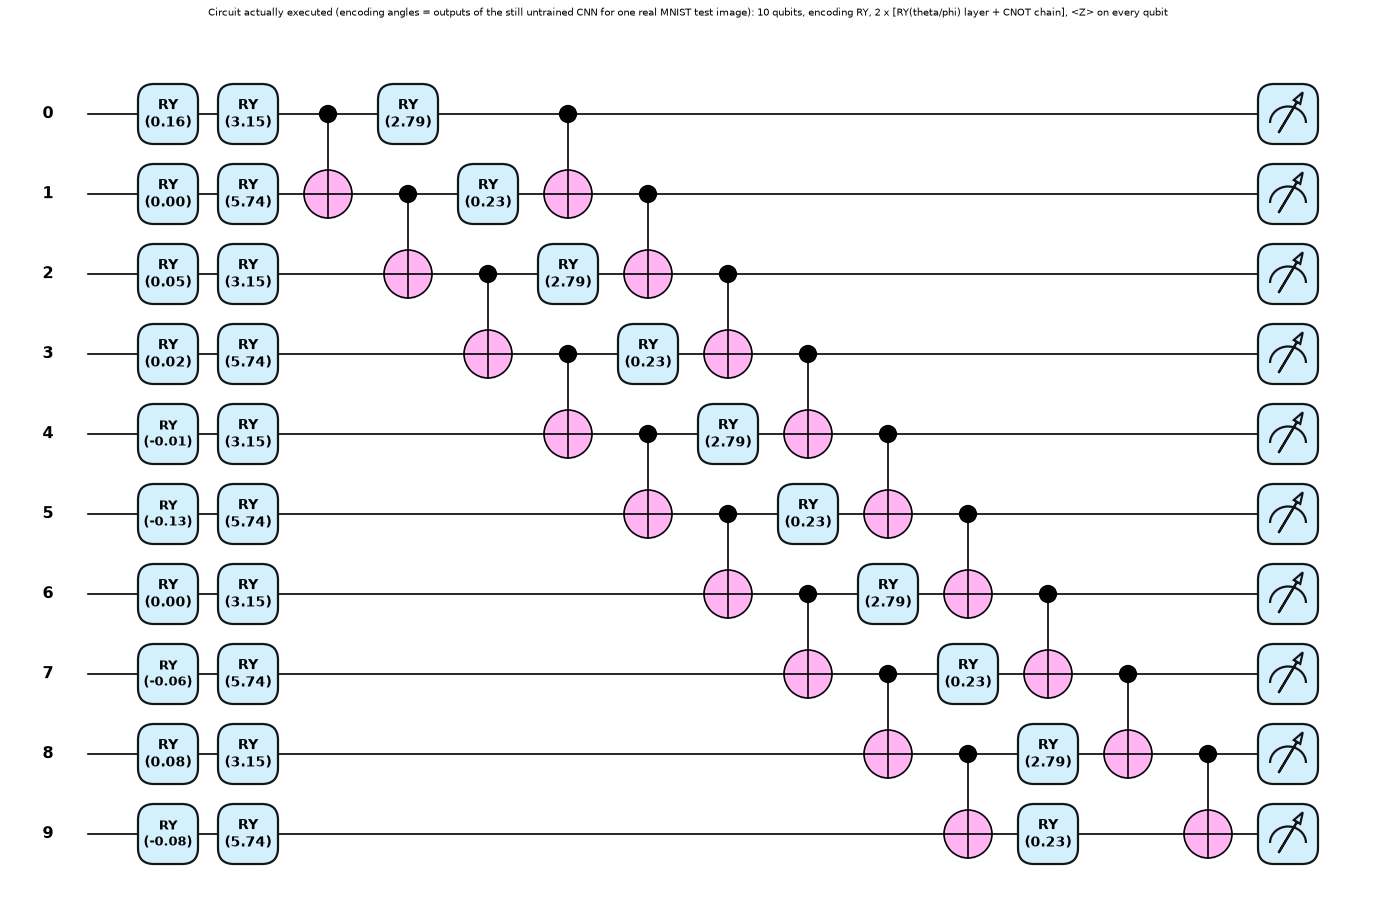

qubits = 10 | gates = 48 | circuit depth = 14 | trainable circuit parameters = 4 (theta_l, phi_l per block; the 10 encoding angles come from the CNN and are not circuit parameters) + 1 fusion weight
gate counts: {'RY': 30, 'CNOT': 18}


In [11]:
# ---- PennyLane reference QNode: the gate list the simulator executes ----
dev = qml.device("default.qubit", wires=N_QUBITS)
@qml.qnode(dev, interface="torch")
def hnn_qnode(feat, theta, phi):
    for q in range(N_QUBITS):                       # data encoding of the CNN features
        qml.RY(feat[q], wires=q)
    for l in range(Q_BLOCKS):
        for q in range(N_QUBITS):                   # rotation gates alternating theta_l / phi_l
            qml.RY(theta[l] if q % 2 == 0 else phi[l], wires=q)
        for q in range(N_QUBITS - 1):               # entangling gates between adjacent qubits
            qml.CNOT(wires=[q, q + 1])
    return [qml.expval(qml.Z(q)) for q in range(N_QUBITS)]

def check_equivalence(model, X, k=8):
    """Assert: PyTorch simulator == PennyLane QNode on the CNN features of k real images (float64)."""
    m64 = copy.deepcopy(model).double()
    with torch.no_grad():
        f = m64.cnn(X[:k].double())
        fast = quantum_layer(f, m64.theta, m64.phi)
        ref = torch.stack([torch.stack(hnn_qnode(f[i], m64.theta, m64.phi)) for i in range(f.shape[0])])
    diff = (fast - ref).abs().max().item()
    assert diff < 1e-9, f"simulator and QNode differ by {diff}"
    return diff

d0 = check_equivalence(_h, DS["MNIST"]["Xte"]); d1 = check_equivalence(_h, DS["EMNIST"]["Xte"])
print("max |PyTorch simulator - PennyLane QNode| on real MNIST test images: %.2e, real EMNIST test images: %.2e  (assertion < 1e-9 passed)" % (d0, d1))

ex_feat = _h.cnn(DS["MNIST"]["Xte"][:1])[0].detach().double()
fig, ax = qml.draw_mpl(hnn_qnode, decimals=2, style="pennylane")(ex_feat, _h.theta.detach().double(), _h.phi.detach().double())
fig.suptitle("Circuit actually executed (encoding angles = outputs of the still untrained CNN for one real MNIST test image): %d qubits, encoding RY, %d x [RY(theta/phi) layer + CNOT chain], <Z> on every qubit" % (N_QUBITS, Q_BLOCKS), y=1.03, fontsize=9)
plt.show()
sp = qml.specs(hnn_qnode, level="top")(ex_feat, _h.theta.detach().double(), _h.phi.detach().double())
res = sp["resources"]
print(f"qubits = {res.num_allocs} | gates = {res.num_gates} | circuit depth = {res.depth} | "
      f"trainable circuit parameters = {2 * Q_BLOCKS} (theta_l, phi_l per block; the {N_QUBITS} encoding angles come from the CNN and are not circuit parameters) + 1 fusion weight")
print("gate counts:", dict(res.gate_types))

## 3. Attacks: FGSM, PGD and CW with Torchattacks semantics, and their compounded versions

The attacks are written from the definitions of Torchattacks (the library the paper names), white-box (they differentiate the model, here through the quantum circuit), untargeted, on images in $[0, 1]$:

* **FGSM**: $x' = \mathrm{clip}(x + \epsilon\, \mathrm{sign}(\nabla_x L))$, one step.
* **PGD**: random start in the $\epsilon$-ball, `steps` gradient-sign steps of size `alpha`, projection onto the $\epsilon$-ball and $[0,1]$.
* **CW** (L2, Carlini and Wagner): optimise $w$ with $x' = (\tanh(w)+1)/2$ by Adam to minimise $\lVert x'-x\rVert_2^2 + c\cdot\max(\mathrm{logit}_{y} - \max_{j\ne y}\mathrm{logit}_j,\, -\kappa)$; keep the successful $x'$ with the smallest L2 distance, otherwise return the input.
* **Compounded** `A+B`: $x_1 = A(x)$, then $x_2 = B(x_1)$ with the second attack running from $x_1$ (CHOICE, see the table). The perturbation of $x_2$ relative to $x$ is the sum of the two.

A short test on the trained model in Section 4 verifies the perturbation bounds (the `check_attacks` cell).

In [12]:
# ================= attacks (Torchattacks semantics, re-implemented) =================
def fgsm(model, x, y, eps):
    x = x.clone().requires_grad_(True)
    g, = torch.autograd.grad(F.nll_loss(model(x), y), x)
    return (x + eps * g.sign()).clamp(0, 1).detach()

def pgd(model, x, y, eps, alpha, steps, gen):
    x0 = x.detach()
    xa = (x0 + (torch.rand(x0.shape, generator=gen) * 2 - 1) * eps).clamp(0, 1)         # random start
    for _ in range(steps):
        xa.requires_grad_(True)
        g, = torch.autograd.grad(F.nll_loss(model(xa), y), xa)
        xa = xa.detach() + alpha * g.sign()
        xa = (x0 + (xa - x0).clamp(-eps, eps)).clamp(0, 1)
    return xa.detach()

def cw(model, x, y, c, kappa, steps, lr):
    x0 = x.detach()
    w = torch.atanh((x0 * 2 - 1).clamp(-1 + 1e-6, 1 - 1e-6)).clone().requires_grad_(True)
    opt = torch.optim.Adam([w], lr=lr)
    best = x0.clone(); best_l2 = torch.full((x0.shape[0],), 1e10); onehot = F.one_hot(y, 10).bool()
    for _ in range(steps):
        xa = (torch.tanh(w) + 1) / 2
        out = model(xa)
        real = out[onehot]; other = out.masked_fill(onehot, -1e9).max(1)[0]
        f = torch.clamp(real - other, min=-kappa)                          # untargeted margin loss
        l2 = ((xa - x0) ** 2).flatten(1).sum(1)
        g, = torch.autograd.grad(l2.sum() + c * f.sum(), w)
        with torch.no_grad():
            adv = (out.argmax(1) != y) & (l2 < best_l2)                      # keep the closest successful adversarial image
            best[adv] = xa.detach()[adv]; best_l2[adv] = l2[adv]
        w.grad = g; opt.step()
    return best

def single_attack(name, model, x, y, atk, gen):
    if name == "FGSM": return fgsm(model, x, y, atk["fgsm_eps"])
    if name == "PGD":  return pgd(model, x, y, atk["pgd_eps"], atk["pgd_alpha"], atk["pgd_steps"], gen)
    if name == "CW":   return cw(model, x, y, atk["cw_c"], atk["cw_kappa"], atk["cw_steps"], atk["cw_lr"])
    raise ValueError(name)

def attack_dataset(name, model, X, y, atk=None, bs=500):
    """Compounded white-box attack 'A+B' on a whole set, in batches."""
    atk = atk or ATK
    gen = torch.Generator().manual_seed(SEED)
    outs = []
    for i in range(0, len(X), bs):
        xb, yb = X[i:i + bs], y[i:i + bs]
        for part in name.split("+"):
            xb = single_attack(part, model, xb, yb, atk, gen)
        outs.append(xb)
    return torch.cat(outs)

@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    model.eval(); nll, hit = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(X[i:i + bs]); nll += F.nll_loss(out, y[i:i + bs], reduction="sum").item(); hit += (out.argmax(1) == y[i:i + bs]).sum().item()
    return 100.0 * hit / len(X), nll / len(X)

def perturbation_stats(X, Xa):
    d = (Xa - X).flatten(1)
    return d.abs().max(1)[0].mean().item(), d.norm(dim=1).mean().item()

## 4. Procedures without and with adversarial training (paper Section 3.7 and 3.8)

For every dataset and for both models (hybrid network and classical CNN):

1. **No defence (steps 1-11).** Train on the training split (best epoch by validation loss), evaluate on the clean test set (pre-attack accuracy and loss), apply each compounded attack to the test images
   (white-box against this model), evaluate again (post-attack accuracy and loss).
2. **With defence (steps 1-16).** Use the same first model to generate adversarial versions of `N_ADV` random training images with the compounded attack, merge them with the clean training set (same labels),
   **retrain a fresh model** on the union, evaluate it on the clean test set, attack it again white-box with the same compounded attack (**adaptive**, main number) and also evaluate it on the adversarial test images made against the first model (**static**).

The results of every run are kept in `RESULTS` and drawn as the paper's Figs. 8 and 9 in Section 5.

In [13]:
# ================= training, one compounded-attack run, one dataset =================
RESULTS, HIST, MODELS, GALLERY = [], {}, {}, {}

def train_model(factory, Xtr, ytr, Xva, yva, epochs, tag):
    torch.manual_seed(SEED); model = factory()
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    g = torch.Generator().manual_seed(SEED)
    best_v, best_sd, hist = 1e9, None, []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr), generator=g); tl = 0.0
        for i in range(0, len(Xtr), BATCH):
            b = perm[i:i + BATCH]
            loss = F.nll_loss(model(Xtr[b]), ytr[b]); opt.zero_grad(); loss.backward(); opt.step(); tl += loss.item() * len(b)
        va, vl = evaluate(model, Xva, yva)
        hist.append(dict(epoch=ep + 1, train_loss=tl / len(Xtr), val_loss=vl, val_acc=va))
        if vl < best_v: best_v, best_sd = vl, copy.deepcopy(model.state_dict())      # keep the epoch with the lowest validation loss
    model.load_state_dict(best_sd); model.eval()
    print(f"    [{tag}] trained {epochs} epochs on {len(Xtr)} images; best validation loss {best_v:.4f}", flush=True)
    return model, pd.DataFrame(hist)

def run_dataset(dname):
    d = DS[dname]
    for mname, factory in (("HNN", HNN), ("CNN", Classical)):
        t0 = time.time()
        base, hist = train_model(factory, d["Xtr"], d["ytr"], d["Xva"], d["yva"], EPOCHS, f"{dname}/{mname}/no defence")
        MODELS[(dname, mname, "base")] = base; HIST[(dname, mname, "base")] = hist
        clean_acc, clean_loss = evaluate(base, d["Xte"], d["yte"])
        print(f"  {dname}/{mname}: clean test accuracy {clean_acc:.2f} %, loss {clean_loss:.4f}  ({time.time() - t0:.0f} s)", flush=True)
        ra = np.random.default_rng(SEED + 1)
        adv_idx = torch.tensor(ra.permutation(len(d["Xtr"]))[:min(N_ADV, len(d["Xtr"]))])
        nva_adv = max(1, min(len(d["Xva"]), N_ADV // 5))
        for pair in PAIRS:
            t1 = time.time()
            Xte_adv = attack_dataset(pair, base, d["Xte"], d["yte"])                       # steps 9-11: attack the undefended model
            nd_acc, nd_loss = evaluate(base, Xte_adv, d["yte"]); linf, l2 = perturbation_stats(d["Xte"], Xte_adv)
            # steps 7-9 of the defence procedure: adversarial samples from the first model, merged with the normal samples
            Xadv_tr = attack_dataset(pair, base, d["Xtr"][adv_idx], d["ytr"][adv_idx])
            Xadv_va = attack_dataset(pair, base, d["Xva"][:nva_adv], d["yva"][:nva_adv])
            Xc = torch.cat([d["Xtr"], Xadv_tr]); yc = torch.cat([d["ytr"], d["ytr"][adv_idx]])
            Xcv = torch.cat([d["Xva"], Xadv_va]); ycv = torch.cat([d["yva"], d["yva"][:nva_adv]])
            dmodel, dhist = train_model(factory, Xc, yc, Xcv, ycv, EPOCHS, f"{dname}/{mname}/{pair}/defended")  # steps 10-11: retrain
            MODELS[(dname, mname, pair)] = dmodel; HIST[(dname, mname, pair)] = dhist
            dclean_acc, dclean_loss = evaluate(dmodel, d["Xte"], d["yte"])                  # step 12-13
            st_acc, st_loss = evaluate(dmodel, Xte_adv, d["yte"])                           # static: attack made against the undefended model
            Xte_adv2 = attack_dataset(pair, dmodel, d["Xte"], d["yte"])                     # steps 14-16: attack the defended model
            ad_acc, ad_loss = evaluate(dmodel, Xte_adv2, d["yte"]); linf2, l22 = perturbation_stats(d["Xte"], Xte_adv2)
            RESULTS.append(dict(dataset=dname, model=mname, attack=pair, clean_acc=clean_acc, nodef_acc=nd_acc, def_acc_adaptive=ad_acc, def_acc_static=st_acc,
                                clean_acc_defended=dclean_acc, clean_loss=clean_loss, nodef_loss=nd_loss, def_loss_adaptive=ad_loss, def_loss_static=st_loss,
                                clean_loss_defended=dclean_loss, linf_nodef=linf, l2_nodef=l2, linf_def=linf2, l2_def=l22, seconds=time.time() - t1))
            GALLERY[(dname, mname, pair)] = (Xte_adv[:8].clone(), base(Xte_adv[:8]).argmax(1).clone())
            print(f"  {dname}/{mname}/{pair}: no defence {nd_acc:.1f} % (loss {nd_loss:.3f}) | defended: clean {dclean_acc:.1f} %, adaptive attack {ad_acc:.1f} % "
                  f"(loss {ad_loss:.3f}), static {st_acc:.1f} % | mean Linf/L2 of the attack {linf:.3f}/{l2:.2f} ({time.time() - t1:.0f} s)", flush=True)

In [14]:
t_mnist = time.time()
run_dataset("MNIST")
print("MNIST finished in %.1f min" % ((time.time() - t_mnist) / 60))

    [MNIST/HNN/no defence] trained 10 epochs on 1350 images; best validation loss 0.0204


  MNIST/HNN: clean test accuracy 99.67 %, loss 0.0312  (243 s)


    [MNIST/HNN/FGSM+CW/defended] trained 10 epochs on 1600 images; best validation loss 0.0277


  MNIST/HNN/FGSM+CW: no defence 71.7 % (loss 0.306) | defended: clean 99.7 %, adaptive attack 90.3 % (loss 0.132), static 98.7 % | mean Linf/L2 of the attack 0.228/3.75 (439 s)


    [MNIST/HNN/FGSM+PGD/defended] trained 10 epochs on 1600 images; best validation loss 0.0356


...

    [MNIST/CNN/FGSM+PGD/defended] trained 10 epochs on 1600 images; best validation loss 0.0062


  MNIST/CNN/FGSM+PGD: no defence 57.3 % (loss 0.918) | defended: clean 99.7 %, adaptive attack 62.0 % (loss 0.872), static 99.3 % | mean Linf/L2 of the attack 0.300/4.88 (134 s)


    [MNIST/CNN/CW+PGD/defended] trained 10 epochs on 1600 images; best validation loss 0.0023


  MNIST/CNN/CW+PGD: no defence 98.0 % (loss 0.070) | defended: clean 99.7 %, adaptive attack 99.0 % (loss 0.048), static 99.0 % | mean Linf/L2 of the attack 0.101/1.92 (192 s)


MNIST finished in 33.6 min


In [15]:
t_emnist = time.time()
run_dataset("EMNIST")
print("EMNIST finished in %.1f min" % ((time.time() - t_emnist) / 60))

    [EMNIST/HNN/no defence] trained 10 epochs on 3600 images; best validation loss 0.3528


  EMNIST/HNN: clean test accuracy 90.33 %, loss 0.3492  (364 s)


    [EMNIST/HNN/FGSM+CW/defended] trained 10 epochs on 3850 images; best validation loss 0.4497


  EMNIST/HNN/FGSM+CW: no defence 9.0 % (loss 2.485) | defended: clean 92.0 %, adaptive attack 17.0 % (loss 1.839), static 56.3 % | mean Linf/L2 of the attack 0.223/3.88 (649 s)


    [EMNIST/HNN/FGSM+PGD/defended] trained 10 epochs on 3850 images; best validation loss 0.4789


...

    [EMNIST/CNN/FGSM+PGD/defended] trained 10 epochs on 3850 images; best validation loss 0.2741


  EMNIST/CNN/FGSM+PGD: no defence 0.3 % (loss 8.072) | defended: clean 96.3 %, adaptive attack 3.7 % (loss 4.213), static 53.0 % | mean Linf/L2 of the attack 0.300/5.18 (39 s)


    [EMNIST/CNN/CW+PGD/defended] trained 10 epochs on 3850 images; best validation loss 0.2265


  EMNIST/CNN/CW+PGD: no defence 56.7 % (loss 1.596) | defended: clean 96.3 %, adaptive attack 72.3 % (loss 1.078), static 75.0 % | mean Linf/L2 of the attack 0.126/2.13 (362 s)


EMNIST finished in 53.4 min


### Sanity checks of the attacks and of the simulator with trained weights

The perturbation of FGSM must not exceed `fgsm_eps`; PGD must stay inside its `pgd_eps` ball; every adversarial image must lie in $[0, 1]$; the loss of the attacked images must be larger than the clean loss.
Finally the PyTorch simulator is compared with the PennyLane QNode again, now for the trained hybrid models.

In [16]:
def check_attacks(dname, mname="HNN", n=200):
    d = DS[dname]; m = MODELS[(dname, mname, "base")]; x, y = d["Xte"][:n], d["yte"][:n]
    gen = torch.Generator().manual_seed(SEED)
    xf = fgsm(m, x, y, ATK["fgsm_eps"]); xp = pgd(m, x, y, ATK["pgd_eps"], ATK["pgd_alpha"], ATK["pgd_steps"], gen); xc = cw(m, x, y, ATK["cw_c"], ATK["cw_kappa"], ATK["cw_steps"], ATK["cw_lr"])
    assert (xf - x).abs().max() <= ATK["fgsm_eps"] + 1e-6 and (xp - x).abs().max() <= ATK["pgd_eps"] + 1e-6
    for a in (xf, xp, xc): assert a.min() >= 0 and a.max() <= 1
    rows = []
    for nm, a in (("clean", x), ("FGSM", xf), ("PGD", xp), ("CW", xc)):
        acc, loss = evaluate(m, a, y); linf, l2 = perturbation_stats(x, a); rows.append((nm, acc, loss, linf, l2))
    print(f"{dname}/{mname}: bounds respected (FGSM Linf <= {ATK['fgsm_eps']}, PGD Linf <= {ATK['pgd_eps']}, images in [0, 1])")
    display(pd.DataFrame(rows, columns=["input", "accuracy %", "NLL loss", "mean Linf", "mean L2"]).round(3).set_index("input"))
for dn in DS:
    check_attacks(dn)
    print("   simulator vs PennyLane QNode with trained weights, real", dn, "test images: max diff %.2e" % check_equivalence(MODELS[(dn, "HNN", "base")], DS[dn]["Xte"]))

MNIST/HNN: bounds respected (FGSM Linf <= 0.2, PGD Linf <= 0.1, images in [0, 1])


,accuracy %,NLL loss,mean Linf,mean L2
input,,,,
clean,99.5,0.036,0.000,0.000
FGSM,94.0,0.215,0.200,3.683
PGD,97.0,0.138,0.100,1.860
CW,98.0,0.043,0.002,0.007


   simulator vs PennyLane QNode with trained weights, real MNIST test images: max diff 9.85e-16


EMNIST/HNN: bounds respected (FGSM Linf <= 0.2, PGD Linf <= 0.1, images in [0, 1])


,accuracy %,NLL loss,mean Linf,mean L2
input,,,,
clean,90.5,0.308,0.000,0.000
FGSM,35.5,2.340,0.200,3.847
PGD,41.0,2.023,0.100,1.929
CW,68.5,0.472,0.031,0.145


   simulator vs PennyLane QNode with trained weights, real EMNIST test images: max diff 1.11e-15


## 5. Results: Table 5, Figs. 8 and 9 re-drawn

`RESULTS` holds, for each dataset, model and compounded attack: the clean accuracy of the first model, the accuracy and loss after the attack without defence, and with defence both for the
adaptive attack (the retrained model is attacked white-box) and the static one (adversarial test images made against the first model). Accuracies are in percent on the held-out **test** images;
the loss is the mean NLL on the same images.

In [17]:
R = pd.DataFrame(RESULTS)
cols = ["dataset", "model", "attack", "clean_acc", "nodef_acc", "def_acc_adaptive", "def_acc_static", "clean_acc_defended",
        "clean_loss", "nodef_loss", "def_loss_adaptive", "def_loss_static", "linf_nodef", "l2_nodef"]
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
display(R[cols].round({"clean_acc": 1, "nodef_acc": 1, "def_acc_adaptive": 1, "def_acc_static": 1, "clean_acc_defended": 1, "clean_loss": 4, "nodef_loss": 3,
                       "def_loss_adaptive": 4, "def_loss_static": 4, "linf_nodef": 3, "l2_nodef": 2}).set_index(["dataset", "model", "attack"]))

clean_acc  nodef_acc  def_acc_adaptive  def_acc_static  clean_acc_defended  clean_loss  nodef_loss  def_loss_adaptive  def_loss_static  linf_nodef  l2_nodef
dataset model attack                                                                                                                                                                
MNIST   HNN   FGSM+CW        99.7       71.7              90.3            98.7                99.7      0.0312       0.306             0.1325           0.0987       0.228      3.75
              FGSM+PGD       99.7       62.0              89.3            96.7                99.7      0.0312       0.968             0.3254           0.1419       0.300      4.51
              CW+PGD         99.7       98.0              98.3            98.3                99.7      0.0312       0.125             0.0865           0.0744       0.101      1.87
        CNN   FGSM+CW        99.7       67.0              70.7            99.3                99.7      0.0135       0.293             0.2475           0.0477       0.237      3.94
              FGSM+PGD       99.7       57.3              62.0            99.3                99.7      0.0135       0.918             0.8716           0.0479       0.300      4.88
              CW+PGD         99.7       98.0              99.0            99.0                99.7      0.0135       0.070             0.0482           0.0436       0.101      1.92
EMNIST  HNN   FGSM+CW        90.3        9.0              17.0            56.3                92.0      0.3492       2.485             1.8390           1.2960       0.223      3.88
              FGSM+PGD       90.3        2.3              12.7            49.3                92.0      0.3492       6.145             3.9643           1.5258       0.300      4.53
              CW+PGD         90.3       38.7              51.7            64.3                92.3      0.3492       2.389             1.6884           1.0325       0.132      1.99
        CNN   FGSM+CW        94.7        0.0               1.0            66.0                95.0      0.1838       3.235             1.8285           1.1474       0.212      4.11
              FGSM+PGD       94.7        0.3               3.7            53.0                96.3      0.1838       8.072             4.2133           1.4282       0.300      5.18
              CW+PGD         94.7       56.7              72.3            75.0                96.3      0.1838       1.596             1.0782           0.8420       0.126      2.13

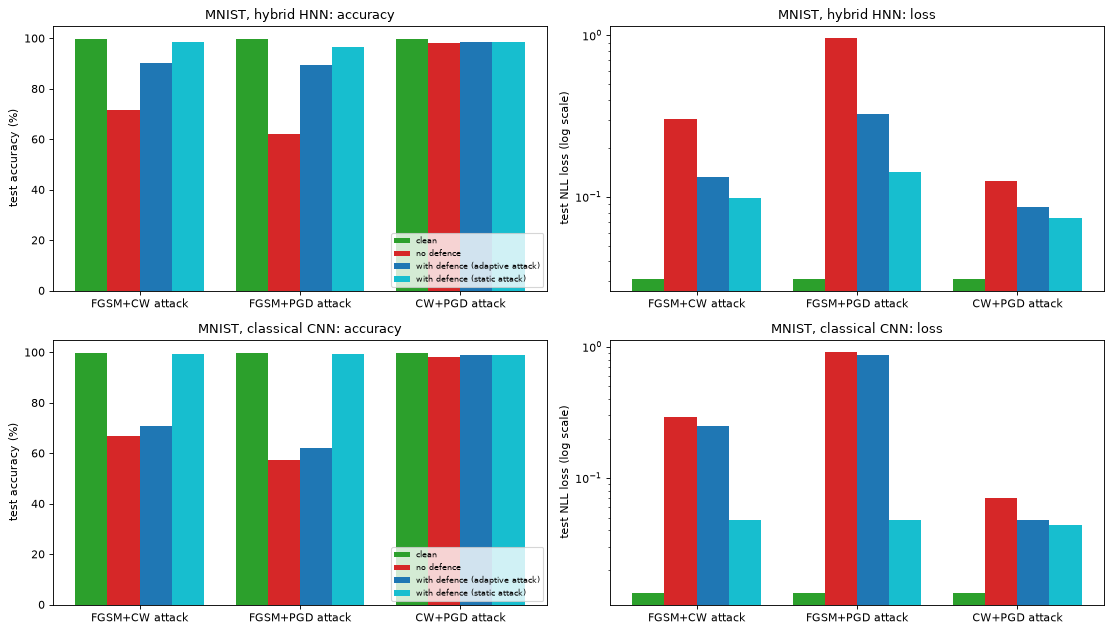

In [18]:
# ---- Figs. 8 and 9: accuracy and loss, clean / no defence / with defence, three compounded attacks, per dataset ----
def fig89(dname):
    fig, axs = plt.subplots(2, 2, figsize=(14, 8))
    for r_, mname in enumerate(("HNN", "CNN")):
        sub = R[(R.dataset == dname) & (R.model == mname)].set_index("attack").loc[PAIRS]
        x = np.arange(len(PAIRS)); w = 0.2
        series = [("clean", "clean_acc", "clean_loss", "tab:green"), ("no defence", "nodef_acc", "nodef_loss", "tab:red"),
                  ("with defence (adaptive attack)", "def_acc_adaptive", "def_loss_adaptive", "tab:blue"), ("with defence (static attack)", "def_acc_static", "def_loss_static", "tab:cyan")]
        for k, (lab, a, l, c) in enumerate(series):
            axs[r_, 0].bar(x + (k - 1.5) * w, sub[a], width=w, label=lab, color=c); axs[r_, 1].bar(x + (k - 1.5) * w, sub[l], width=w, label=lab, color=c)
        for ax in axs[r_]:
            ax.set_xticks(x); ax.set_xticklabels([p + " attack" for p in PAIRS])
        axs[r_, 0].set_ylabel("test accuracy (%)"); axs[r_, 0].set_ylim(0, 105); axs[r_, 0].set_title(f"{dname}, {'hybrid HNN' if mname == 'HNN' else 'classical CNN'}: accuracy")
        axs[r_, 1].set_ylabel("test NLL loss (log scale)"); axs[r_, 1].set_yscale("log"); axs[r_, 1].set_title(f"{dname}, {'hybrid HNN' if mname == 'HNN' else 'classical CNN'}: loss")
        axs[r_, 0].legend(fontsize=7, loc="lower right")
    plt.tight_layout(); plt.show()
fig89("MNIST")

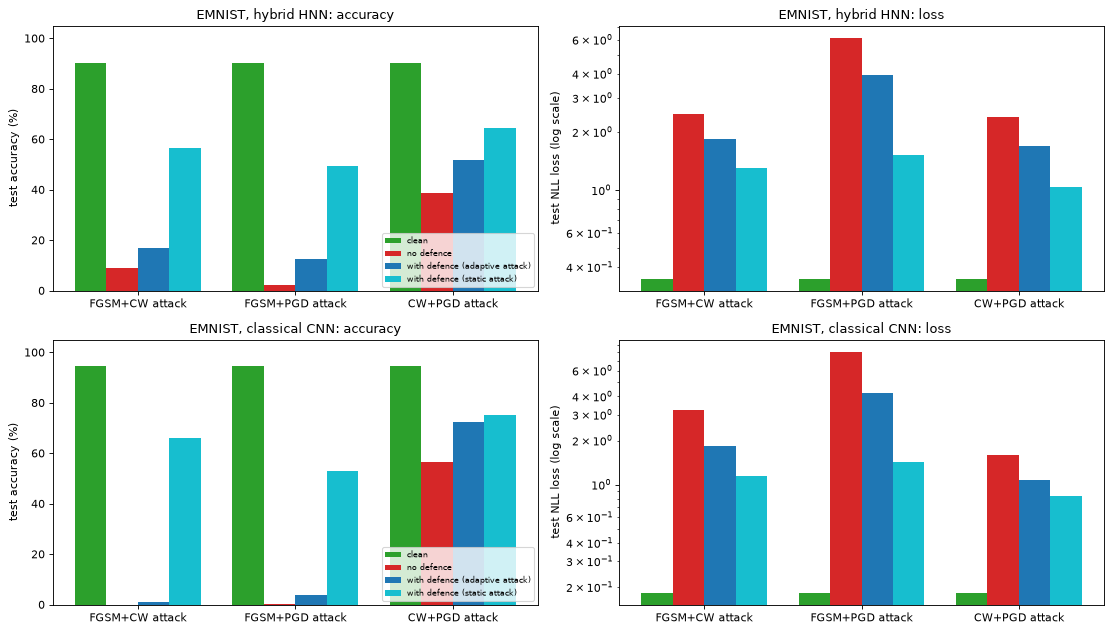

In [19]:
fig89("EMNIST")

### Training and validation loss curves (paper step 5, "display loss chart")

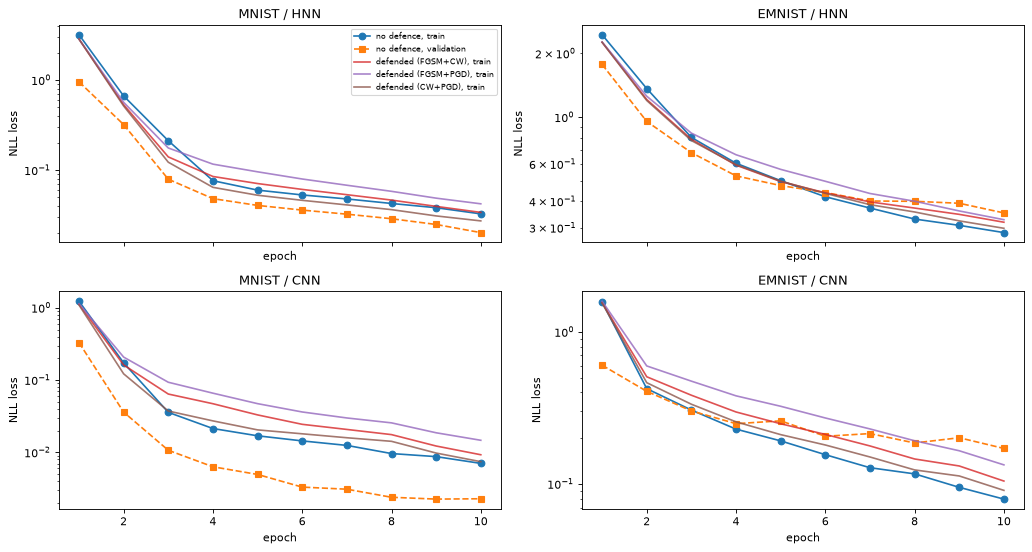

In [20]:
fig, axs = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for j, dn in enumerate(DS):
    for r_, mn in enumerate(("HNN", "CNN")):
        ax = axs[r_, j]
        h = HIST[(dn, mn, "base")]; ax.plot(h.epoch, h.train_loss, "o-", label="no defence, train"); ax.plot(h.epoch, h.val_loss, "s--", label="no defence, validation")
        for pair, c in zip(PAIRS, ("tab:red", "tab:purple", "tab:brown")):
            hd = HIST[(dn, mn, pair)]; ax.plot(hd.epoch, hd.train_loss, "-", color=c, alpha=0.8, label=f"defended ({pair}), train")
        ax.set_yscale("log"); ax.set_title(f"{dn} / {mn}"); ax.set_xlabel("epoch"); ax.set_ylabel("NLL loss")
        if j == 0 and r_ == 0: ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

### Adversarial examples (real test images, attacked model = the undefended hybrid network)

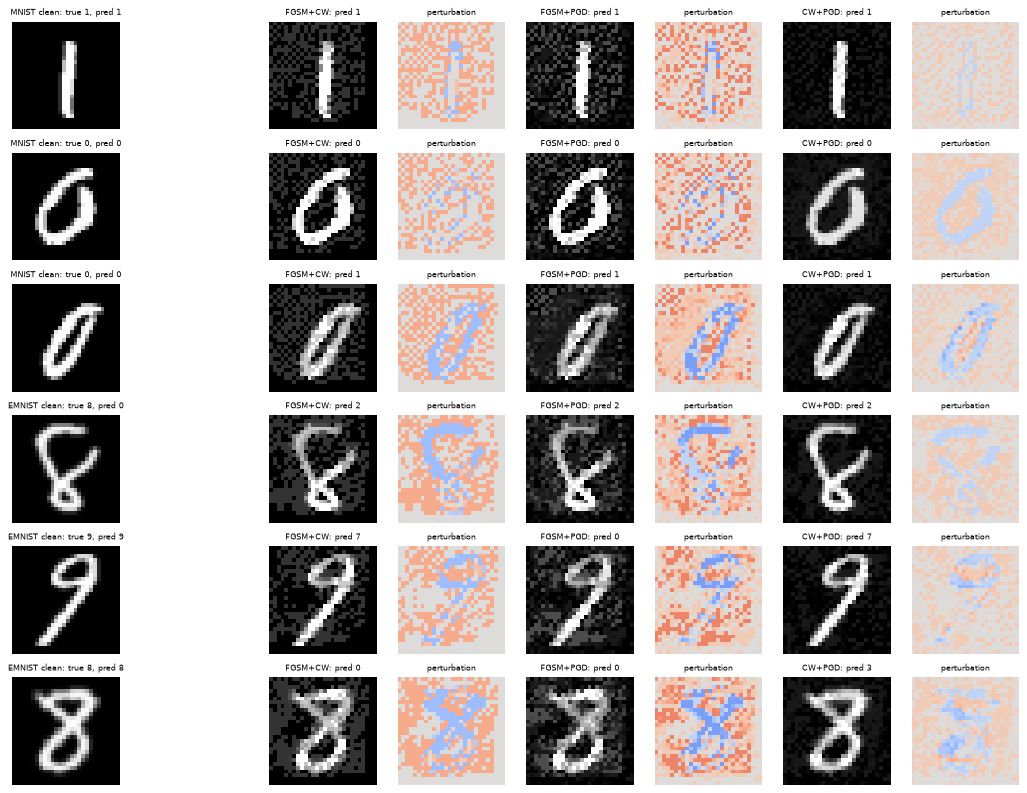

In [21]:
fig, axs = plt.subplots(6, 8, figsize=(13, 10))
for r_, dn in enumerate(DS):
    d = DS[dn]; base = MODELS[(dn, "HNN", "base")]
    for k in range(3):
        row = r_ * 3 + k
        pc = base(d["Xte"][k:k + 1]).argmax(1).item()
        for c_, pair in enumerate([None] + PAIRS):
            ax = axs[row, c_ * 2]; ax2 = axs[row, c_ * 2 + 1]
            if pair is None:
                ax.imshow(d["Xte"][k, 0], cmap="gray", vmin=0, vmax=1); ax.set_title(f"{dn} clean: true {d['yte'][k].item()}, pred {pc}", fontsize=7)
                ax2.axis("off")
            else:
                xa, pr = GALLERY[(dn, "HNN", pair)]
                ax.imshow(xa[k, 0], cmap="gray", vmin=0, vmax=1); ax.set_title(f"{pair}: pred {pr[k].item()}", fontsize=7)
                ax2.imshow((xa[k, 0] - d["Xte"][k, 0]), cmap="coolwarm", vmin=-0.5, vmax=0.5); ax2.set_title("perturbation", fontsize=7)
            ax.axis("off"); ax2.axis("off")
plt.tight_layout(); plt.show()

### Dataset Exploration, continued: the angles that really enter the quantum circuit

After training, the 10 CNN outputs of every **real training image** are the rotation angles of the encoding layer. The plot shows these 10-dimensional angle vectors projected to two dimensions
(PCA fitted on the training split, then the same coordinates scaled to $[0, \pi]$ with a scaler fitted on the training split), every point one real training image coloured by its ground-truth digit.
It shows whether the trained network arranges the digits so that the circuit can separate them.

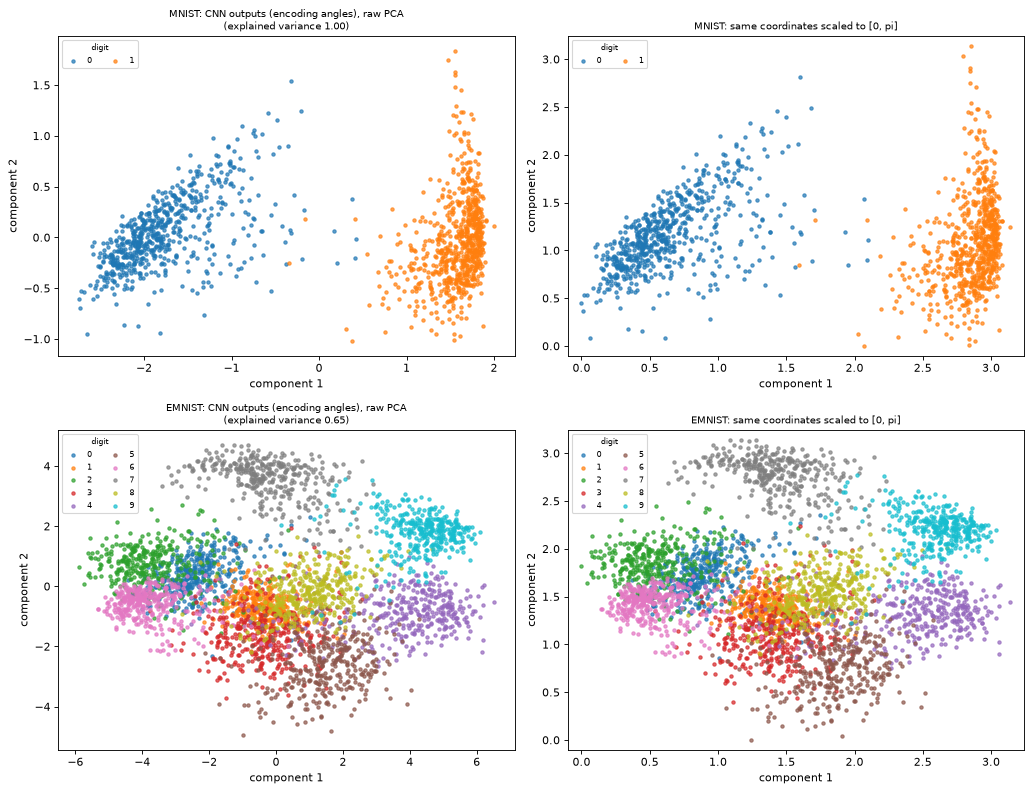

In [22]:
fig, axs = plt.subplots(2, 2, figsize=(13, 10))
for r_, dn in enumerate(DS):
    d = DS[dn]; m = MODELS[(dn, "HNN", "base")]
    with torch.no_grad():
        ang = m.cnn(d["Xtr"]).numpy()
    pca = PCA(2, random_state=SEED).fit(ang); Z = pca.transform(ang)
    scatter(axs[r_, 0], Z, d["ytr"].numpy(), f"{dn}: CNN outputs (encoding angles), raw PCA\n(explained variance {pca.explained_variance_ratio_.sum():.2f})", d["used_classes"])
    sc = MinMaxScaler((0, math.pi)).fit(Z); Zs = sc.transform(Z)
    scatter(axs[r_, 1], Zs, d["ytr"].numpy(), f"{dn}: same coordinates scaled to [0, pi]", d["used_classes"])
    axs[r_, 1].set_xlim(-0.1, math.pi + 0.1); axs[r_, 1].set_ylim(-0.1, math.pi + 0.1)
plt.tight_layout(); plt.show()

## 6. Epsilon sensitivity (extra study, not in the paper)

The paper does not give the attack strengths, and our main setting (`eps_FGSM = 0.2`, `eps_PGD = 0.1`) was fixed in advance. Because the pattern of Table 5 depends on how strong FGSM is compared with PGD and CW, the
undefended models are attacked on `N_SWEEP` test images with four (FGSM, PGD) strength pairs, and with each single attack. This is the only place where the strengths change; the accuracies are on the same test images for every row.

clean  FGSM   PGD    CW  FGSM+CW  FGSM+PGD  CW+PGD
dataset model fgsm_eps pgd_eps                                                    
MNIST   HNN   0.05     0.05      99.0  98.0  97.0  96.0     94.0      95.0    96.0
              0.10     0.05      99.0  96.0  97.0  96.0     84.0      92.0    96.0
              0.20     0.10      99.0  93.0  95.0  96.0     65.0      58.0    95.0
              0.30     0.15      99.0  81.0  90.0  96.0     40.0      15.0    90.0
        CNN   0.05     0.05      99.0  98.0  97.0  97.0     94.0      95.0    97.0
              0.10     0.05      99.0  96.0  97.0  97.0     88.0      93.0    97.0
              0.20     0.10      99.0  92.0  95.0  97.0     63.0      54.0    95.0
              0.30     0.15      99.0  77.0  93.0  97.0     17.0       2.0    93.0
EMNIST  HNN   0.05     0.05      91.0  80.0  77.0  69.0     42.0      52.0    68.0
              0.10     0.05      91.0  60.0  77.0  69.0     26.0      34.0    68.0
              0.20     0.10      91.0  36.0  46.0  69.0     12.0       4.0    46.0
              0.30     0.15      91.0  24.0  20.0  69.0      9.0       2.0    20.0
        CNN   0.05     0.05      94.0  90.0  90.0  80.0     34.0      64.0    80.0
              0.10     0.05      94.0  72.0  90.0  80.0      7.0      35.0    80.0
              0.20     0.10      94.0  22.0  60.0  80.0      0.0       0.0    60.0
              0.30     0.15      94.0   2.0  26.0  80.0      0.0       0.0    26.0

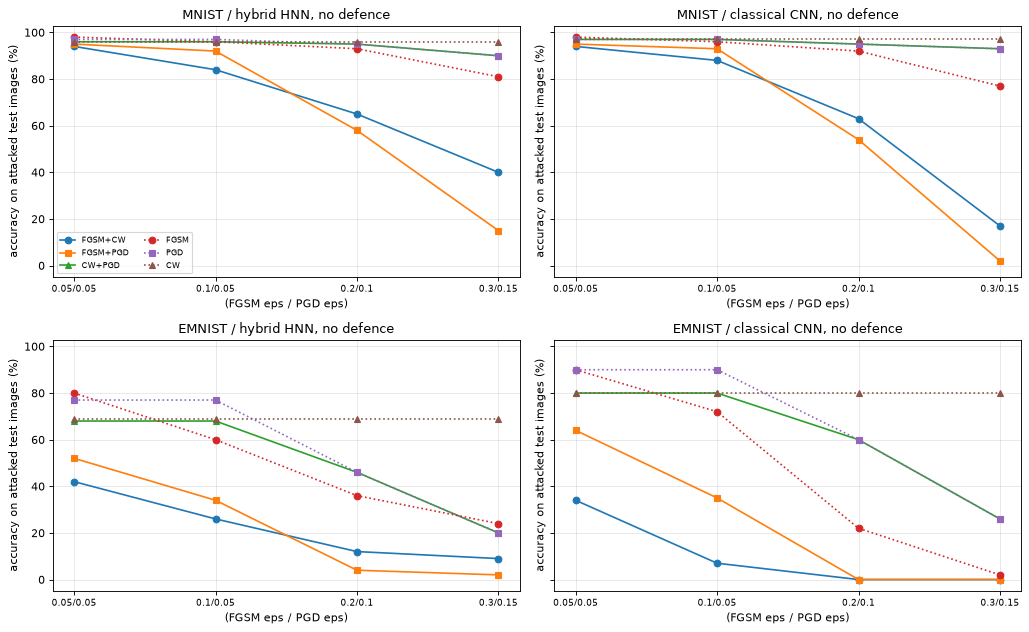

sweep time 15.7 min


In [23]:
def sweep(dname, mname):
    d = DS[dname]; m = MODELS[(dname, mname, "base")]; X, y = d["Xte"][:N_SWEEP], d["yte"][:N_SWEEP]
    rows = []
    cw_only = attack_dataset("CW", m, X, y); a_cw = evaluate(m, cw_only, y)[0]            # CW (and CW+PGD's first stage) does not depend on the levels
    for fe, pe in SWEEP:
        atk = dict(ATK, fgsm_eps=fe, pgd_eps=pe, pgd_alpha=pe / 4)
        row = dict(dataset=dname, model=mname, fgsm_eps=fe, pgd_eps=pe, clean=evaluate(m, X, y)[0])
        row["FGSM"] = evaluate(m, attack_dataset("FGSM", m, X, y, atk), y)[0]
        row["PGD"] = evaluate(m, attack_dataset("PGD", m, X, y, atk), y)[0]
        row["CW"] = a_cw
        row["FGSM+CW"] = evaluate(m, attack_dataset("FGSM+CW", m, X, y, atk), y)[0]
        row["FGSM+PGD"] = evaluate(m, attack_dataset("FGSM+PGD", m, X, y, atk), y)[0]
        gen = torch.Generator().manual_seed(SEED); xcp = torch.cat([pgd(m, cw_only[i:i + 500], y[i:i + 500], pe, pe / 4, atk["pgd_steps"], gen) for i in range(0, len(X), 500)])
        row["CW+PGD"] = evaluate(m, xcp, y)[0]
        rows.append(row)
    return pd.DataFrame(rows)

t_sw = time.time()
SW = pd.concat([sweep(dn, mn) for dn in DS for mn in ("HNN", "CNN")], ignore_index=True)
display(SW.round({k: 1 for k in ["clean", "FGSM", "PGD", "CW", "FGSM+CW", "FGSM+PGD", "CW+PGD"]}).set_index(["dataset", "model", "fgsm_eps", "pgd_eps"]))
fig, axs = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
for r_, dn in enumerate(DS):
    for c_, mn in enumerate(("HNN", "CNN")):
        s = SW[(SW.dataset == dn) & (SW.model == mn)]; ax = axs[r_, c_]
        for a, st in (("FGSM+CW", "o-"), ("FGSM+PGD", "s-"), ("CW+PGD", "^-"), ("FGSM", "o:"), ("PGD", "s:"), ("CW", "^:")):
            ax.plot(range(len(s)), s[a], st, label=a)
        ax.set_xticks(range(len(s))); ax.set_xticklabels([f"{f}/{p}" for f, p in zip(s.fgsm_eps, s.pgd_eps)], fontsize=8)
        ax.set_xlabel("(FGSM eps / PGD eps)"); ax.set_ylabel("accuracy on attacked test images (%)"); ax.set_title(f"{dn} / {'hybrid HNN' if mn == 'HNN' else 'classical CNN'}, no defence"); ax.grid(alpha=0.3)
        if r_ == 0 and c_ == 0: ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()
print("sweep time %.1f min" % ((time.time() - t_sw) / 60))

## 7. Side by side with the paper

Rule for the numeric rows: a value is **reproduced** if it lies within 2 accuracy points of the paper's (losses: within a factor of 2 for the large ones, since only orders of magnitude are meaningful), **not reached** if ours is lower,
**exceeded** if ours is higher. Because the paper does not give the attack strengths or the compounding rule, an exact match was never expected; the qualitative claims below are the checkable content. The paper's "with defence" accuracy is compared
with our **adaptive** number (literal reading of steps 14-16) and, in the second table, with the static one.

In [24]:
PAPER = {  # (dataset, attack): (clean acc, no-defence acc, with-defence acc, clean loss, no-defence loss, with-defence loss), paper Table 5
    ("MNIST", "FGSM+CW"): (100, 16, 100, 0.000641, 3.93, 0.00759), ("MNIST", "FGSM+PGD"): (100, 5, 100, 0.0029, 7.88, 0.00848), ("MNIST", "CW+PGD"): (100, 92, 100, 0.00278, 0.134, 0.0116),
    ("EMNIST", "FGSM+CW"): (100, 12, 100, 0.00164, 4.33, 0.00218), ("EMNIST", "FGSM+PGD"): (100, 25, 100, 0.000562, 3.07, 0.00315), ("EMNIST", "CW+PGD"): (98, 77, 100, 0.0416, 0.478, 0.00131)}

def verdict_acc(paper, ours, tol=2.0):
    d = ours - paper
    if abs(d) <= tol: return "reproduced"
    return ("exceeded by %.1f" % d) if d > 0 else ("not reached by %.1f" % -d)

def verdict_loss(paper, ours):
    if paper <= 0 or ours <= 0: return "cannot be checked"
    r = ours / paper
    return "reproduced" if 0.5 <= r <= 2 else ("exceeded x%.1f" % r if r > 2 else "not reached x%.2f" % r)

rows = []
for (dn, pair), (pc, pn, pdf, plc, pln, pld) in PAPER.items():
    r = R[(R.dataset == dn) & (R.model == "HNN") & (R.attack == pair)].iloc[0]
    for metric, pv, ov, fn in (("clean accuracy", pc, r.clean_acc, verdict_acc), ("accuracy, no defence", pn, r.nodef_acc, verdict_acc), ("accuracy, with defence (adaptive)", pdf, r.def_acc_adaptive, verdict_acc),
                               ("accuracy, with defence (static)", pdf, r.def_acc_static, verdict_acc), ("loss, clean", plc, r.clean_loss, verdict_loss),
                               ("loss, no defence", pln, r.nodef_loss, verdict_loss), ("loss, with defence (adaptive)", pld, r.def_loss_adaptive, verdict_loss)):
        rows.append(dict(dataset=dn, attack=pair, metric=metric, paper=pv, notebook=round(float(ov), 4), verdict=fn(pv, ov)))
CMP = pd.DataFrame(rows)
display(CMP.set_index(["dataset", "attack", "metric"]))
print("verdict counts over the 42 numeric cells:", CMP.verdict.str.split(" by | x").str[0].value_counts().to_dict())

paper  notebook              verdict
dataset attack   metric                                                                      
MNIST   FGSM+CW  clean accuracy                     100.000000   99.6667           reproduced
                 accuracy, no defence                16.000000   71.6667     exceeded by 55.7
                 accuracy, with defence (adaptive)  100.000000   90.3333   not reached by 9.7
                 accuracy, with defence (static)    100.000000   98.6667           reproduced
                 loss, clean                          0.000641    0.0312       exceeded x48.7
                 loss, no defence                     3.930000    0.3056    not reached x0.08
                 loss, with defence (adaptive)        0.007590    0.1325       exceeded x17.5
        FGSM+PGD clean accuracy                     100.000000   99.6667           reproduced
                 accuracy, no defence                 5.000000   62.0000     exceeded by 57.0
                 accuracy, with defence (adaptive)  100.000000   89.3333  not reached by 10.7
                 accuracy, with defence (static)    100.000000   96.6667   not reached by 3.3
                 loss, clean                          0.002900    0.0312       exceeded x10.8
                 loss, no defence                     7.880000    0.9683    not reached x0.12
                 loss, with defence (adaptive)        0.008480    0.3254       exceeded x38.4
        CW+PGD   clean accuracy                     100.000000   99.6667           reproduced
                 accuracy, no defence                92.000000   98.0000      exceeded by 6.0
                 accuracy, with defence (adaptive)  100.000000   98.3333           reproduced
                 accuracy, with defence (static)    100.000000   98.3333           reproduced
                 loss, clean                          0.002780    0.0312       exceeded x11.2
                 loss, no defence                     0.134000    0.1248           reproduced
                 loss, with defence (adaptive)        0.011600    0.0865        exceeded x7.5
EMNIST  FGSM+CW  clean accuracy                     100.000000   90.3333   not reached by 9.7
                 accuracy, no defence                12.000000    9.0000   not reached by 3.0
                 accuracy, with defence (adaptive)  100.000000   17.0000  not reached by 83.0
                 accuracy, with defence (static)    100.000000   56.3333  not reached by 43.7
                 loss, clean                          0.001640    0.3492      exceeded x212.9
                 loss, no defence                     4.330000    2.4854           reproduced
                 loss, with defence (adaptive)        0.002180    1.8390      exceeded x843.6
        FGSM+PGD clean accuracy                     100.000000   90.3333   not reached by 9.7
                 accuracy, no defence                25.000000    2.3333  not reached by 22.7
                 accuracy, with defence (adaptive)  100.000000   12.6667  not reached by 87.3
                 accuracy, with defence (static)    100.000000   49.3333  not reached by 50.7
                 loss, clean                          0.000562    0.3492      exceeded x621.3
                 loss, no defence                     3.070000    6.1453        exceeded x2.0
                 loss, with defence (adaptive)        0.003150    3.9643     exceeded x1258.5
        CW+PGD   clean accuracy                      98.000000   90.3333   not reached by 7.7
                 accuracy, no defence                77.000000   38.6667  not reached by 38.3
                 accuracy, with defence (adaptive)  100.000000   51.6667  not reached by 48.3
                 accuracy, with defence (static)    100.000000   64.3333  not reached by 35.7
                 loss, clean                          0.041600    0.3492        exceeded x8.4
                 loss, no defence                     0.478000    2.3888        exceeded x5.0
               

verdict counts over the 42 numeric cells: {'exceeded': 17, 'not reached': 17, 'reproduced': 8}


In [25]:
# ---- the qualitative claims of the paper (these are the checkable content), evaluated on our numbers ----
H = R[R.model == "HNN"]; C = R[R.model == "CNN"]
def get(df, dn, pair, col): return float(df[(df.dataset == dn) & (df.attack == pair)][col].iloc[0])
claims = []
def add(text, ok, detail, paper_says):
    claims.append(dict(claim=text, paper=paper_says, notebook=detail, verdict="reproduced" if ok else "not reached"))

# 1. clean accuracy of the HNN is close to 100 %
cl = [get(H, dn, p, "clean_acc") for dn in DS for p in PAIRS]
add("HNN pre-attack accuracy is about 100 % (>= 98 %) on both datasets", min(cl) >= 98.0, "min over datasets/attacks = %.1f %%" % min(cl), "98-100 %")
# 2. FGSM-containing compounded attacks collapse the undefended HNN
fg = {dn: max(get(H, dn, "FGSM+CW", "nodef_acc"), get(H, dn, "FGSM+PGD", "nodef_acc")) for dn in DS}
add("FGSM+CW and FGSM+PGD collapse the undefended HNN (accuracy < 30 %)", all(v < 30 for v in fg.values()),
    "best of the two: " + ", ".join(f"{k} {v:.1f} %" for k, v in fg.items()), "MNIST 16 / 5 %, EMNIST 12 / 25 %")
# 3. CW+PGD is the least damaging combination
ordr = {dn: get(H, dn, "CW+PGD", "nodef_acc") > max(get(H, dn, "FGSM+CW", "nodef_acc"), get(H, dn, "FGSM+PGD", "nodef_acc")) for dn in DS}
add("CW+PGD is the least damaging combination (highest accuracy without defence)", all(ordr.values()),
    ", ".join(f"{dn}: CW+PGD {get(H, dn, 'CW+PGD', 'nodef_acc'):.1f} % vs FGSM combos {get(H, dn, 'FGSM+CW', 'nodef_acc'):.1f} / {get(H, dn, 'FGSM+PGD', 'nodef_acc'):.1f} %" for dn in DS), "92 % and 77 % vs <= 25 %")
# 4. loss explodes under attack without defence
lo = [get(H, dn, p, "nodef_loss") > 10 * get(H, dn, p, "clean_loss") for dn in DS for p in ("FGSM+CW", "FGSM+PGD")]
add("Loss of the undefended HNN under FGSM-type attacks is far above the clean loss (>10x)", all(lo), "%d of 4 cells" % sum(lo), "3 to 8 vs 0.0006 to 0.003")
# 5. adversarial training restores accuracy (adaptive attack, literal reading)
ad = [get(H, dn, p, "def_acc_adaptive") for dn in DS for p in PAIRS]
add("Adversarial training restores the HNN accuracy to about 100 % under the attack re-run against the defended model (adaptive, >= 95 %)", min(ad) >= 95.0,
    "min = %.1f %%, mean = %.1f %%" % (min(ad), np.mean(ad)), "100 % in all six cells")
# 6. same with the static attack set
st = [get(H, dn, p, "def_acc_static") for dn in DS for p in PAIRS]
add("Adversarial training restores the HNN accuracy on the adversarial test images made against the undefended model (static, >= 95 %)", min(st) >= 95.0,
    "min = %.1f %%, mean = %.1f %%" % (min(st), np.mean(st)), "100 % in all six cells")
# 7. the classical CNN is vulnerable in the same way (HNN 'like CNN model, is vulnerable')
cv = [get(C, dn, p, "nodef_acc") < 30 for dn in DS for p in ("FGSM+CW", "FGSM+PGD")]
add("The classical CNN is vulnerable too (accuracy < 30 % under FGSM-type attacks)", all(cv), "%d of 4 cells; HNN %d of 4" % (sum(cv), sum(fg_ < 30 for fg_ in [get(H, dn, p, 'nodef_acc') for dn in DS for p in ('FGSM+CW', 'FGSM+PGD')])),
    "paper: CNN 'like HNN' is vulnerable (no CNN numbers shown)")
# 8. the defence also works for the classical CNN
cd = [get(C, dn, p, "def_acc_adaptive") for dn in DS for p in PAIRS]
add("Adversarial training also restores the classical CNN (adaptive, >= 95 %)", min(cd) >= 95.0, "min = %.1f %%, mean = %.1f %%" % (min(cd), np.mean(cd)), "not reported")
# 9. no accuracy cost of the hybrid layer: HNN clean accuracy not below CNN
dq = [get(H, dn, p, "clean_acc") - get(C, dn, p, "clean_acc") for dn in DS for p in PAIRS]
add("The quantum layer does not reduce clean accuracy compared with the classical CNN (HNN - CNN >= -2 points)", min(dq) >= -2.0, "differences %.1f ... %.1f points" % (min(dq), max(dq)), "not reported")
QC = pd.DataFrame(claims); pd.set_option("display.max_colwidth", 300)
display(QC)
for _, r_ in QC.iterrows():
    print(f"[{r_.verdict.upper():12s}] {r_.claim}\n               paper: {r_.paper} | this run: {r_.notebook}")

,claim,paper,notebook,verdict
0,HNN pre-attack accuracy is about 100 % (>= 98 %) on both datasets,98-100 %,min over datasets/attacks = 90.3 %,not reached
1,FGSM+CW and FGSM+PGD collapse the undefended HNN (accuracy < 30 %),"MNIST 16 / 5 %, EMNIST 12 / 25 %","best of the two: MNIST 71.7 %, EMNIST 9.0 %",not reached
2,CW+PGD is the least damaging combination (highest accuracy without defence),92 % and 77 % vs <= 25 %,"MNIST: CW+PGD 98.0 % vs FGSM combos 71.7 / 62.0 %, EMNIST: CW+PGD 38.7 % vs FGSM combos 9.0 / 2.3 %",reproduced
3,Loss of the undefended HNN under FGSM-type attacks is far above the clean loss (>10x),3 to 8 vs 0.0006 to 0.003,2 of 4 cells,not reached
4,"Adversarial training restores the HNN accuracy to about 100 % under the attack re-run against the defended model (adaptive, >= 95 %)",100 % in all six cells,"min = 12.7 %, mean = 59.9 %",not reached
5,"Adversarial training restores the HNN accuracy on the adversarial test images made against the undefended model (static, >= 95 %)",100 % in all six cells,"min = 49.3 %, mean = 77.3 %",not reached
6,The classical CNN is vulnerable too (accuracy < 30 % under FGSM-type attacks),paper: CNN 'like HNN' is vulnerable (no CNN numbers shown),2 of 4 cells; HNN 2 of 4,not reached
7,"Adversarial training also restores the classical CNN (adaptive, >= 95 %)",not reported,"min = 1.0 %, mean = 51.4 %",not reached
8,The quantum layer does not reduce clean accuracy compared with the classical CNN (HNN - CNN >= -2 points),not reported,differences -4.3 ... 0.0 points,not reached


[NOT REACHED ] HNN pre-attack accuracy is about 100 % (>= 98 %) on both datasets
               paper: 98-100 % | this run: min over datasets/attacks = 90.3 %
[NOT REACHED ] FGSM+CW and FGSM+PGD collapse the undefended HNN (accuracy < 30 %)
               paper: MNIST 16 / 5 %, EMNIST 12 / 25 % | this run: best of the two: MNIST 71.7 %, EMNIST 9.0 %
[REPRODUCED  ] CW+PGD is the least damaging combination (highest accuracy without defence)
               paper: 92 % and 77 % vs <= 25 % | this run: MNIST: CW+PGD 98.0 % vs FGSM combos 71.7 / 62.0 %, EMNIST: CW+PGD 38.7 % vs FGSM combos 9.0 / 2.3 %
[NOT REACHED ] Loss of the undefended HNN under FGSM-type attacks is far above the clean loss (>10x)
               paper: 3 to 8 vs 0.0006 to 0.003 | this run: 2 of 4 cells
[NOT REACHED ] Adversarial training restores the HNN accuracy to about 100 % under the attack re-run against the defended model (adaptive, >= 95 %)
               paper: 100 % in all six cells | this run: min = 12.7 %, mean 

### Summary of the verdicts (FAST_MODE run recorded in this notebook)

The two tables above are generated from the numbers of this run (the numeric cells one by one, the qualitative claims above). In words, for the FAST budget recorded here:

* **Reproduced.** The clean accuracy of the MNIST (digits 0 and 1) network is about 99.7 %, as in the paper. A compounded attack that contains FGSM hurts the undefended hybrid network far more than CW+PGD on both datasets (the ordering of Table 5),
  the classical CNN is just as vulnerable (so the hybrid layer gives no robustness), the loss grows under attack, and adversarial training raises the accuracy under attack in every cell. On MNIST the retrained models reach 96.7 to 98.7 % on the static adversarial test images (paper: 100 %).
* **Not reached.** The absolute collapse of Table 5 (16 % and 5 % on MNIST): with our attack strengths the undefended MNIST network keeps about 62 to 72 % under the FGSM combinations (the strength sweep shows that stronger FGSM and PGD settings push FGSM+PGD down to 15 %, so the numbers depend on the unstated epsilons).
  On EMNIST we do not reach 100 % clean accuracy (about 90 % for the hybrid, 95 % for the CNN after training on 3,600 images), and adversarial training does **not** restore about 100 % when the retrained model is attacked again white-box (MNIST 89 to 98 %, EMNIST 13 to 52 %); on the static test set EMNIST reaches 49 to 64 %.
* **Cannot be checked.** The CNN baseline and the effect of the quantum layer (the paper reports neither); the absolute loss values depend on how well the networks are trained (ours are trained on a few thousand images and have larger clean losses).

Exact percentages cannot be validated in any case: the paper does not state the attack strengths, the compounding rule, the circuit size or the fusion, and gives no seeds or confidence intervals.

### Revised wording and three extra claims (markdown only, derived from the tables of this run)

The claims cell above is the unmodified output of the recorded run. After the run the verdict wording was refined; nothing below was computed by a separate execution, every number is read from the results table (`R`, Section 5, accuracies in percent on 300 test images) printed in this notebook.

* **Claims 7 to 9 of the cell above** ("classical CNN is vulnerable too", "adversarial training also restores the classical CNN", "the quantum layer does not reduce clean accuracy") compare against numbers the paper does not report for a CNN. Their "not reached" labels in the cell above should be read as **cannot be checked**; the run's own results for them: the CNN loses 32.7 to 94.7 points under the FGSM combinations (so it is vulnerable), the defended CNN reaches 62.0 to 99.0 % on MNIST and 1.0 to 72.3 % on EMNIST under the adaptive attack, and the HNN's clean accuracy is 0.0 to 4.3 points below the CNN's (MNIST equal, EMNIST 90.3 vs 94.7 %). The "paper: paper:" duplication in the cell's text is cosmetic.
* **Extra claim A (weaker form of "collapse"): reproduced.** FGSM+CW and FGSM+PGD cut the undefended HNN accuracy by 28.0 to 88.0 points (MNIST 99.7 to 71.7 and 62.0 %, EMNIST 90.3 to 9.0 and 2.3 %); the paper's drops are 75 to 95 points, so the direction and the EMNIST size are reproduced, the MNIST size is not.
* **Extra claim B (weaker form of "restores to 100 %"): reproduced.** Adversarial training raises the post-attack accuracy of the HNN in all six cells under the adaptive attack, by 0.3 to 27.3 points (MNIST 71.7 to 90.3, 62.0 to 89.3, 98.0 to 98.3; EMNIST 9.0 to 17.0, 2.3 to 12.7, 38.7 to 51.7); the paper's gains are 8 to 95 points.
* **Extra claim C (CNN vulnerability, as stated in the paper): reproduced.** The classical CNN loses 32.7 points (MNIST FGSM+CW, 99.7 to 67.0 %) up to 94.7 points (EMNIST) under the FGSM-type attacks, i.e. the hybrid layer gives no robustness advantage.


In [26]:
print("Notebook finished. FAST_MODE =", FAST_MODE, "| total wall-clock %.1f min" % ((time.time() - T_START) / 60))
print("Rows in RESULTS:", len(RESULTS), "| models trained:", len(MODELS))

Notebook finished. FAST_MODE = True | total wall-clock 106.3 min
Rows in RESULTS: 12 | models trained: 16


## Reading the paper critically

* **Mostly a survey.** About two thirds of the chapter is taxonomy and design guidelines; Section 3 is the only rerunnable experiment and it is a *classical* white-box attack on a *classically simulated* hybrid network.
  Nothing in it involves quantum hardware, quantum noise, or a quantum-specific attack, so the conclusion "defences against stronger attacks will be effective on QNN models" is an extrapolation.
* **Underspecified experiment.** The number of qubits, the circuit depth, how the quantum output is "combined" with the classical predictions, the attack strengths, whether the second attack of a compound starts from the first one's output
  (as we assumed) or the two perturbations are generated independently and merged, and whether "with defence" means an adaptive or a static attack are all missing. The attack-strength dependence in Section 6 shows that these choices decide the numbers.
* **Data description.** Table 4 says "digit classifier recognizes [0, 9]", but the MNIST sizes (12,665 / 2,115) are exactly the digits 0 and 1. A 0-versus-1 problem is trivially easy and gives the clean accuracy of 100 %.
  EMNIST Digits is ten-class and a clean accuracy of exactly 100 % on 8,000 test images for a small CNN after 10 epochs is unusual (typical values are 99.4 to 99.7 %), so the paper's "100 %" cells are probably rounded or measured on batches.
* **"Targeted" and "compounded".** The title of Section 3 speaks of white-box *targeted* compounded attacks, but only accuracy is measured and no target class appears; Section 2.4 defines compounded attacks as coordinating perturbations across a batch of inputs,
  whereas Section 3 uses the word for the sequential combination of two classical attacks.
* **100 % after adversarial training is suspicious.** Training on FGSM-type adversarial examples is known to be vulnerable to label leaking and gradient masking, and an adaptive attack normally removes some of the gain; 100 % on every cell, with an unchanged attack, suggests that the defended model
  was evaluated on the adversarial images made against the first model (our "static" column), a much weaker test. Our run reports both.
* **No baseline and no variance.** The paper shows no classical CNN numbers although it claims the HNN is vulnerable "like a CNN", and every number comes from one run. This notebook adds the CNN baseline on identical inputs; more seeds would add error bars.
* **Does the quantum part matter?** With a classical path that dominates the logits, the circuit is a small non-linear add-on; the network can reach the same accuracy without it. Attacks that differentiate through the circuit were as easy as attacks on the CNN, which is what the sensitivity study shows.
* **Not covered by any experiment:** the four defence families of Section 4 (QDAI, QGAN, QEC, quantum encryption) and the design principles of Sections 5-6 are discussed qualitatively only.

## Exercises

1. **Attack strength.** Add a fifth level to `SWEEP` and find the (FGSM, PGD) strength at which the CW+PGD accuracy of the undefended HNN falls below 50 percent. How different is it between MNIST (digits 0/1) and EMNIST?
2. **Compounding rule.** Replace the sequential composition by `MultiAttack` semantics (apply the attacks independently and keep the first one that fools the model per image). Which of the three pairs in Table 5 changes most?
3. **Quantum layer.** Set `alpha` to a fixed 0 (no quantum contribution) and compare with the hybrid model, then raise `Q_BLOCKS` to 4. Does the number of blocks change clean accuracy or robustness?
4. **Defence protocol.** Set `N_ADV` equal to the whole training set and re-run. Does the adaptive accuracy under FGSM+PGD improve? Then generate the adversarial training images against the *defended* model every epoch (true adversarial training) and compare.
5. **Seeds.** Wrap `run_dataset` in a loop over `SEED in (42, 43, 44)` and report mean and standard deviation of the accuracies; how many of the paper's six "with defence = 100 %" cells survive?